# Q2C | Analyze Relationships Between Attributes

> *Analyze the relationships between the data attributes, and between the data attributes and label. This involves computing the Pearson Correlation Coefficient (PCC) and generating scatter plots.*

---

#### IMPORTANT

This dataset has no `train` / `test` split of its own, so the same chronological split as Q2B is made at the top of this notebook: the earliest 584 days are `train` and the latest 147 days are `test`. Every statistic and every score below is computed on the training rows only, so no analysis or treatment decision is influenced by the test data (`data snooping`).

# Answer Summary

**What was done:** a scatter matrix of the continuous attributes and `Rentals`, a Pearson (lower) vs Spearman (upper) correlation matrix of all 11 attributes and `Rentals`, a collinearity check, a combination gain check and three row count tables for the categorical attributes. Then single attribute interventions: each one reshapes or re-encodes one attribute inside a `LinearRegression` pipeline and is compared with the raw column (A) on the same 20 folds, using Δrmse vs A, the one-standard-error rule and a Holm adjusted p.

**Attributes vs label**

| Attribute | Pearson r | Spearman ρ | A r2 (raw) | Main shape carried forward | r2 (Δrmse vs A) | Spline ceiling r2 |
|---|---|---|---|---|---|---|
| FeelsLike | 0.69 | 0.70 | 0.463 | Flat top `max(0, t - x)`, t near 0.57 to 0.60 | 0.512 (-60.315) | 0.513 |
| Temp | 0.68 | 0.70 | 0.456 | Flat top `max(0, t - x)`, t near 0.57 or 0.58 | 0.505 (-60.003) | 0.499 |
| Year | 0.54 | 0.51 | 0.279 | As it is (0 / 1) | | |
| Weather | -0.31 | -0.30 | 0.079 | One-hot | 0.085 (-5.307) | |
| Season | 0.29 | 0.33 | 0.070 | One-hot | 0.345 (-279.003) | |
| Month | 0.20 | 0.28 | 0.028 | Sine / cosine | 0.423 (-404.460) | |
| Wind | -0.20 | -0.19 | 0.023 | Raw, no treatment | | -0.032 |
| Humidity | -0.13 | -0.12 | 0.005 | Hinge alone `max(0, x - t)`, t near 0.75 | 0.045 (-37.099) | 0.044 |
| IsHoliday | -0.05 | -0.06 | -0.011 | Candidate to drop | | |
| IsWorkday | 0.04 | 0.04 | -0.013 | Candidate to drop | | |
| Weekday | 0.04 | 0.04 | -0.015 | Drop | | |

The threshold shapes are reported with their nested variant, where t is searched inside each fold. The spline ceiling was only run for the continuous attributes.

- **Linear relationships with Rentals:** FeelsLike (r = 0.69), Temp (0.68) and Year (0.54) are moderate. Weather (-0.31), Season (0.29), Month (0.20) and Wind (-0.20) are weak. Humidity (-0.13), IsHoliday (-0.05), IsWorkday (0.04) and Weekday (0.04) are very weak. Weather, Wind, Humidity and IsHoliday are the negative ones.
- **PCC badly understates the multi-level codes.** Month has r = 0.20 and a raw r2 of 0.028, but 0.424 once it is one-hot encoded, the best single categorical score. Season goes from 0.070 to 0.345. The code order is not the order of the Rentals means, and r can only see a straight line.
- **For the continuous and binary attributes, the PCC ranking holds under cross validation.** The raw single attribute LR (A) ranks them in the same order as |r|: FeelsLike (r2 0.463), Temp (0.456), Year (0.279), Wind (0.023), Humidity (0.005), then IsHoliday and IsWorkday below 0.

**Relationships between attributes**

- **Temp and FeelsLike are redundant** (r = 0.997), and so are **Season and Month** (r = 0.862). Only one of each pair should carry forward.
- **IsWorkday is fully determined by Weekday and IsHoliday** in the row count table.
- **Year and Month are tied together by the split** (r = -0.36): months 9 to 12 have no second year rows in train.
- **Year adds the most on top of temperature:** the multiple R rises from 0.690 to 0.847 for FeelsLike + Year (Cohen f² 0.852).
- No other pair is above 0.7. The next strongest is Humidity and Weather (0.59).

**Shapes found in the scatter plots and confirmed by the interventions**

- **Temp and FeelsLike rise, then go flat.** The flat top is significant for both (`p (Holm)` 0.013 and 0.002 for B nested), with the bend picked between 0.55 and 0.59 in every fold. Keeping a slope above the bend adds nothing, so the downturn in Q2B's FeelsLike hinge is not real. The squared term gains the least of the shapes.
- **Humidity only matters once it is high.** The hinge alone is significant (B nested `p (Holm)` 0.004), with t = 0.75 picked in 12 of 20 folds, but the attribute stays weak (best r2 0.054). Its single 0.0 value does not distort the fit (Δ -1.371).
- **Wind has no shape worth fitting.** No intervention beats the raw column, and fixing its skew (log, Yeo-Johnson) makes it worse.
- **Month is one smooth wave.** The sine / cosine encoding ties one-hot (rmse 1348.604 vs 1347.629) with 2 coefficients instead of 11.
- **Weather's rare level carries signal.** Merging level 3 (18 rows) into level 2 is worse than A (Δ +22.591).
- **Weekday, IsHoliday and IsWorkday show no relationship with Rentals.** None of them scores better than the mean-only model (rmse 1788.425).
- **The flexible spline ceiling never clearly beats the simple shapes** (FeelsLike 1238.527 vs 1239.809, Temp 1255.175 vs 1248.142, Humidity 1739.320 vs 1738.048), and it is the worst and least stable option for Wind.

**Carried forward to the multi-feature model**

- **FeelsLike** with a flat top (Temp as the fallback, never both).
- **Year** as it is.
- **Month** with the sine / cosine encoding (one-hot as the alternative), ahead of Season.
- **Weather** one-hot, with level 3 kept.
- **Humidity** with the high-side hinge, and **Wind** raw, each only if it improves the model.
- **Candidates to drop:** Weekday, IsHoliday and IsWorkday.

**Two limits on these scores**

- **The folds are shuffled,** so the scores describe days inside the training period and are optimistic compared with the chronological test set. Q2D uses time-ordered folds.
- **Month and Season are scored without Year,** so their gains include part of the year effect. Q2D scores them with `Year` in the model.

---

# Imports

In [1]:
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, PolynomialFeatures, PowerTransformer, SplineTransformer

from Q2.consts import *

from utils import (
	read_csv_to_df,
	PLOTTING,
	STATISTICS,
	PIPELINES,
	SCORING,
	FEATURES,
)

from Q2.utils import (
	chronological_split,
	Q2_PLOTTING,
	Q2_FEATURES,
)

# Fetch Data

In [2]:
df = read_csv_to_df(path=DATA_PATH, parse_dates=["dteday"])
df = df.rename(columns=SHORT_NAMES)

# Train / Test Split

In [3]:
train_df, test_df = chronological_split(df=df, date_col="Date", test_size=TEST_SIZE)

pd.DataFrame({
	"rows": [len(train_df), len(test_df)],
	"% of rows": [round(len(train_df) / len(df) * 100, 2), round(len(test_df) / len(df) * 100, 2)],
	"first date": [f"{train_df['Date'].min():%Y-%m-%d}", f"{test_df['Date'].min():%Y-%m-%d}"],
	"last date": [f"{train_df['Date'].max():%Y-%m-%d}", f"{test_df['Date'].max():%Y-%m-%d}"],
}, index=["train", "test"])

,rows,% of rows,first date,last date
train,584,79.89,2011-01-01,2012-08-06
test,147,20.11,2012-08-07,2012-12-31


The same chronological split as Q2B. `test_df` is not used again in this notebook.

# Attribute Groups

In [4]:
CONTINUOUS = ["Temp", "FeelsLike", "Humidity", "Wind"]
BINARY = ["Year", "IsHoliday", "IsWorkday"]
MULTI_LEVEL = ["Season", "Month", "Weekday", "Weather"]

ATTRIBUTES = CONTINUOUS + BINARY + MULTI_LEVEL

print(f"{len(ATTRIBUTES)} attributes: {', '.join(ATTRIBUTES)}")
print(f"left out: {', '.join(col for col in train_df.columns if col not in ATTRIBUTES + [TARGET])}")

11 attributes: Temp, FeelsLike, Humidity, Wind, Year, IsHoliday, IsWorkday, Season, Month, Weekday, Weather
left out: ID, Date, Casual, Registered


- **Continuous (4):** the measurements from Q2B.
- **Binary (3):** categorical attributes that are already 0 / 1.
- **Multi-level (4):** categorical attributes stored as a code with more than 2 levels.
- **Left out:** `ID` and `Date` (one distinct value per row) and `Casual` and `Registered` (they add up to `Rentals`), as concluded in Q2B.

# Attribute vs Attribute

## Scatter Matrix

The four continuous attributes and `Rentals`. The categorical attributes are left out: a scatter of two codes only shows a grid of points.

array([[<Axes: xlabel='Temp', ylabel='Temp'>,
        <Axes: xlabel='FeelsLike', ylabel='Temp'>,
        <Axes: xlabel='Humidity', ylabel='Temp'>,
        <Axes: xlabel='Wind', ylabel='Temp'>,
        <Axes: xlabel='Rentals', ylabel='Temp'>],
       [<Axes: xlabel='Temp', ylabel='FeelsLike'>,
        <Axes: xlabel='FeelsLike', ylabel='FeelsLike'>,
        <Axes: xlabel='Humidity', ylabel='FeelsLike'>,
        <Axes: xlabel='Wind', ylabel='FeelsLike'>,
        <Axes: xlabel='Rentals', ylabel='FeelsLike'>],
       [<Axes: xlabel='Temp', ylabel='Humidity'>,
        <Axes: xlabel='FeelsLike', ylabel='Humidity'>,
        <Axes: xlabel='Humidity', ylabel='Humidity'>,
        <Axes: xlabel='Wind', ylabel='Humidity'>,
        <Axes: xlabel='Rentals', ylabel='Humidity'>],
       [<Axes: xlabel='Temp', ylabel='Wind'>,
        <Axes: xlabel='FeelsLike', ylabel='Wind'>,
        <Axes: xlabel='Humidity', ylabel='Wind'>,
        <Axes: xlabel='Wind', ylabel='Wind'>,
        <Axes: xlabel='Rentals', 

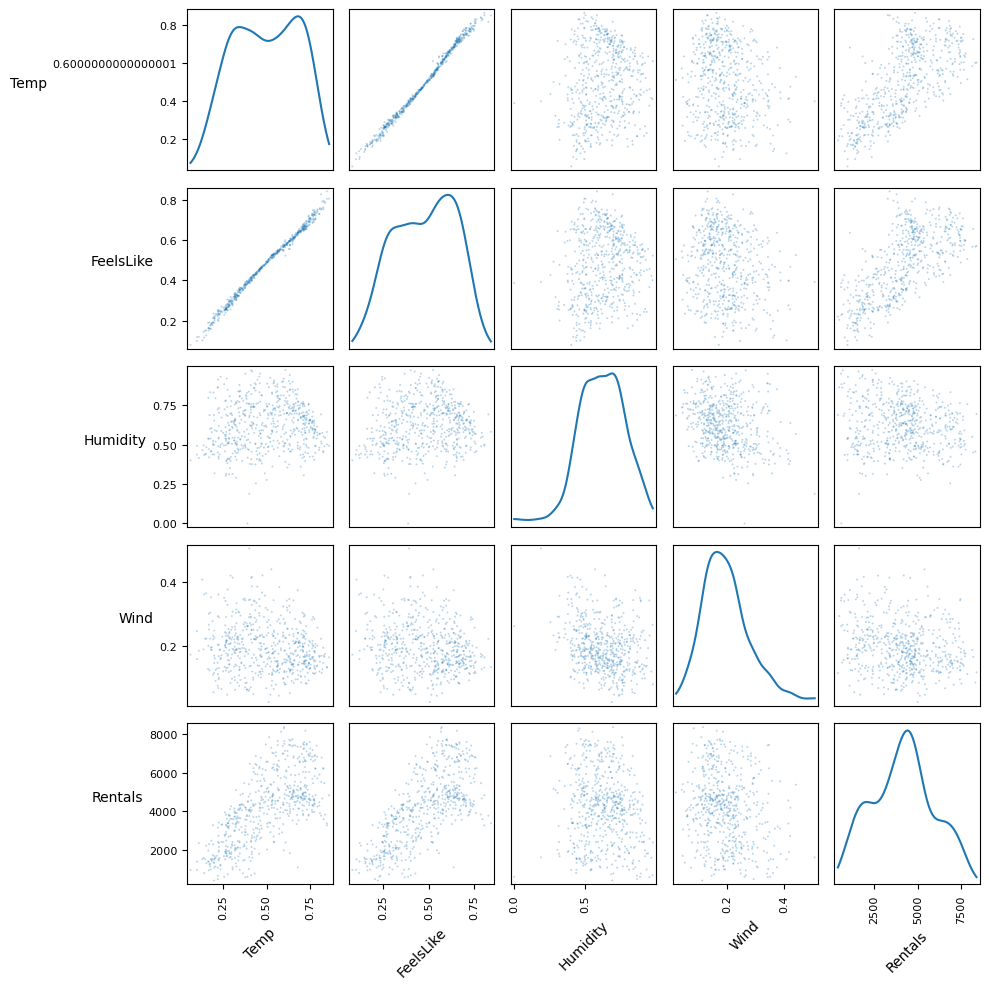

In [5]:
PLOTTING.scatter_matrix(df=train_df[CONTINUOUS + [TARGET]])

## Correlation

Pearson r (lower left) and Spearman rho (upper right) for all 11 attributes and `Rentals`.

- For the continuous and binary attributes, r reads the usual way.
- For the multi-level codes (`Season`, `Month`, `Weekday`, `Weather`), r treats the code as a quantity. It only picks up a relationship that moves in one direction along the code order, so a low r there does not mean no relationship. Q2B's level means R² is the better guide for those four.

<Axes: title={'center': 'Pearson (lower) vs Spearman (upper) Correlation Matrix (train)'}>

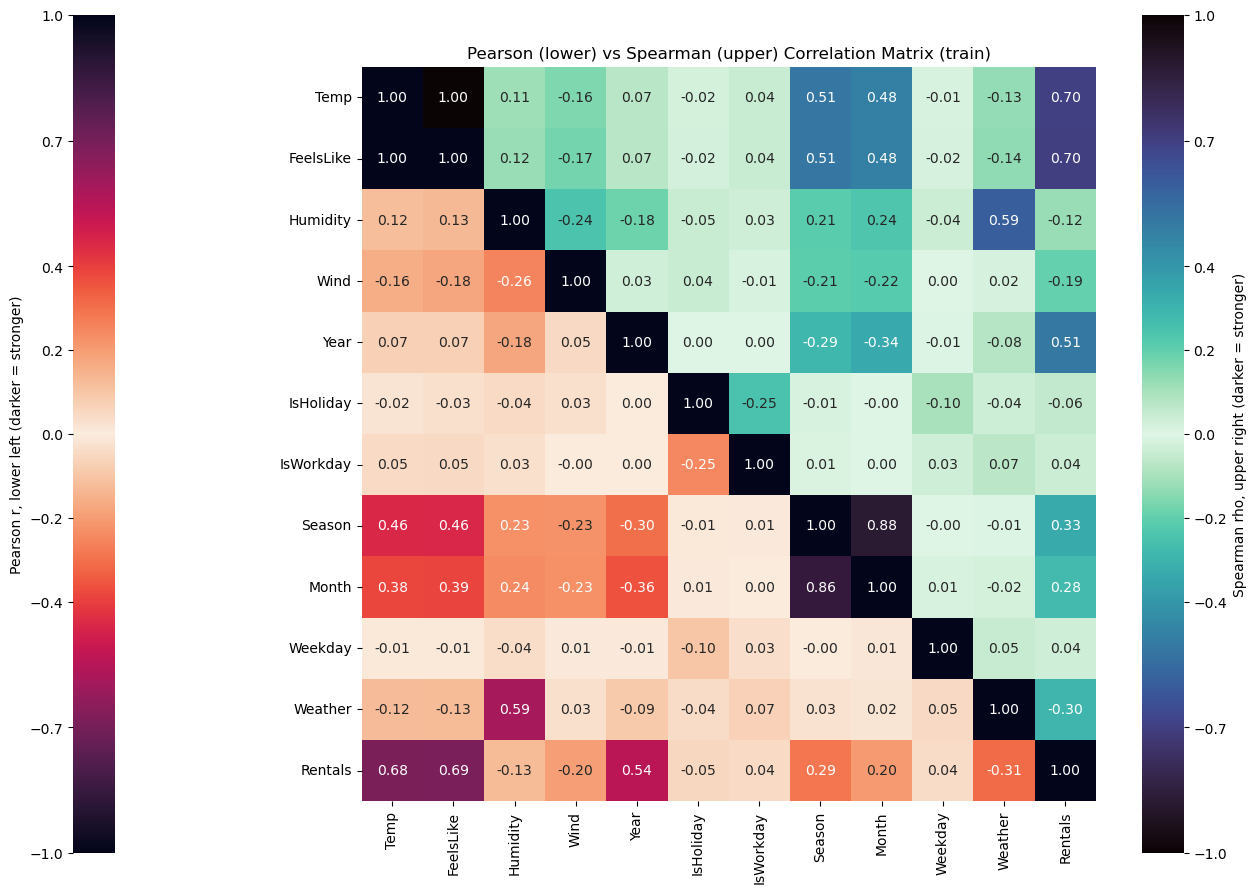

In [6]:
PLOTTING.correlation_matrix(
	pearson=train_df[ATTRIBUTES + [TARGET]].corr(),
	spearman=train_df[ATTRIBUTES + [TARGET]].corr(method='spearman'),
	title='Pearson (lower) vs Spearman (upper) Correlation Matrix (train)',
	figsize=(14, 9),
)

### Collinearity

Every pair of attributes ranked by how strongly they correlate with each other. A pair above the threshold says close to the same thing, so one of the two is redundant.

In [7]:
STATISTICS.collinearity_df(df=train_df[ATTRIBUTES],
						  # feature_pearson_threshold=0.7, filter=True # defaults
)

,rows used,Pearson r between features,|r| between features > 0.7,outcome
Temp + FeelsLike,584,0.997,True,"redundant: keep one, or use Ridge"
Season + Month,584,0.862,True,"redundant: keep one, or use Ridge"


### Combination Gain

How much a second (then a third) attribute adds on top of the best single attribute (then the best pair). Only the continuous and binary attributes are combined here, since this check reads every column as a quantity.

In [8]:
STATISTICS.combination_gain_df(df=train_df[CONTINUOUS + BINARY], target=train_df[TARGET],
							   # size=2, cohen_f2_threshold=0.15, filter=True # defaults
)

,rows used,baseline features,added feature,baseline Pearson R,all features Pearson R,Pearson R gain,baseline Spearman rho,all features Spearman rho,Spearman rho gain,cohen f²,cohen f² ≥ 0.15,outcome
FeelsLike + Year,584,FeelsLike,Year,0.690,0.847,0.157,0.703,0.845,0.142,0.852,True,keep together
Temp + Year,584,Temp,Year,0.685,0.843,0.158,0.699,0.842,0.143,0.835,True,keep together


In [9]:
STATISTICS.combination_gain_df(df=train_df[CONTINUOUS + BINARY], target=train_df[TARGET], size=3,
							   # cohen_f2_threshold=0.15, filter=True # defaults
)

,rows used,baseline features,added feature,baseline Pearson R,all features Pearson R,Pearson R gain,baseline Spearman rho,all features Spearman rho,Spearman rho gain,cohen f²,cohen f² ≥ 0.15,outcome


## Category Overlap

Pearson r cannot show whether one code repeats another, so the categorical attributes are compared with row counts. A table where each row has a single non-zero cell means the row attribute fully determines the column attribute.

In [10]:
pd.crosstab(train_df["Month"], train_df["Season"])

Season,1,2,3,4
Month,,,,
1,62,0,0,0
2,57,0,0,0
3,40,22,0,0
4,0,60,0,0
5,0,62,0,0
6,0,40,20,0
7,0,0,62,0
8,0,0,37,0
9,0,0,22,8


In [11]:
pd.crosstab(train_df["Weekday"], [train_df["IsHoliday"], train_df["IsWorkday"]])

IsHoliday   0       1
IsWorkday   0   1   0
Weekday              
0          84   0   0
1           0  72  12
2           0  83   0
3           0  82   1
4           0  82   1
5           0  81   2
6          84   0   0

In [12]:
pd.crosstab(train_df["Month"], train_df["Year"])

Year,0,1
Month,,
1,31,31
2,28,29
3,31,31
4,30,30
5,31,31
6,30,30
7,31,31
8,31,6
9,30,0


## Attribute vs Attribute Results

- **Temp and FeelsLike say the same thing.** Their Pearson r is 0.997, and the scatter matrix shows the two on a single tight line. `collinearity_df` flags the pair as redundant.
- **Season and Month are the second redundant pair** (r = 0.862). In the `Month` by `Season` table, 8 of the 12 months fall in a single season, and months 3, 6, 9 and 12 are split across two.
- **No other pair of attributes is above the 0.7 threshold.** The next strongest are Humidity and Weather (0.59), Temp and Season (0.46, Spearman 0.51) and Temp and Month (0.38, Spearman 0.48).
- **Year and Month are negatively correlated (-0.36), and that comes from the split.** In the `Month` by `Year` table, months 1 to 7 are split evenly between the years, month 8 has 31 and 6 rows, and months 9 to 12 have no second year rows at all.
- **IsWorkday is fully determined by Weekday and IsHoliday.** Weekdays 0 and 6 are never working days (84 rows each). Weekdays 1 to 5 are working days except for the 16 holiday rows, and no row is both a holiday and a working day.
- **Year adds the most on top of temperature.** Adding Year lifts the multiple R from 0.690 to 0.847 for FeelsLike (Cohen f² 0.852) and from 0.685 to 0.843 for Temp (f² 0.835). No third continuous or binary attribute reaches the 0.15 threshold on top of a pair (the size 3 table is empty).
- **Attributes vs Rentals (Pearson r):** FeelsLike 0.69, Temp 0.68 and Year 0.54 are moderate. Weather (-0.31), Season (0.29), Month (0.20) and Wind (-0.20) are weak. Humidity (-0.13), IsHoliday (-0.05), IsWorkday (0.04) and Weekday (0.04) are very weak. Spearman gives the same ranking, with Month the furthest from its Pearson value (0.28 vs 0.20).

#### Carry forward

- **Use only one of Temp and FeelsLike** in the multi-feature model.
- **Use only one of Season and Month,** or check that keeping both adds something.
- **IsWorkday adds nothing that Weekday and IsHoliday do not already hold.**
- **Keep Year with the temperature attribute.**

# Attribute Interventions

Each attribute is tested on its own against `Rentals`. Every intervention is a `Pipeline` of a transform then `LinearRegression`, fit inside each training fold. The interventions for an attribute come from what Q2B found for that attribute, so the list differs from one attribute to the next.

**Folds (note)**

- Every intervention is scored on the same 20 folds: 4-fold cross validation repeated over 5 seeds (`SEEDS`), made from the train rows only. No attribute has missing values, so every attribute uses all the train rows and the same folds.
- **The folds are shuffled.** The train rows are consecutive days, so a validation day usually has training days on both sides of it. The scores therefore say how well a shape fits days inside the training period. That is the question in this notebook: is the relationship bent, is one-hot better than the code.
- **The scores are optimistic compared with the test set,** which holds the days after the training period.
- The comparison between interventions is still fair. Every intervention is scored on the same folds, and a one-attribute linear model has no way to use the neighboring days.
- **Q2D switches to time-ordered folds** (train on the earlier days, validate on the days that follow), since that is where the score is meant to predict test performance.

**Variants of a threshold intervention**

- **fixed** variants use the threshold t that Q2B reported.
- **nested** variants search t with an inner 4-fold CV inside each training fold, keeping only thresholds that leave at least 5% of the training fold's rows on each side (the same guard as Q2B), so the picked t never sees the validation fold.

**Noise threshold (Δrmse vs A)**

- Every intervention is compared with A on the same 20 folds, using the per-fold rmse differences d (intervention minus A). A negative Δ means lower error than A.
- The folds share most of their training rows, so their scores are not independent. The SE of the mean difference is corrected with the Nadeau and Bengio factor: `SE = sqrt(var(d) · (1/20 + n_test/n_train))`.
- `Δ / SE` is the corrected t statistic and `p` is its one-sided p-value for "lower rmse than A".
- `verdict` follows the one-standard-error rule:
  - **within noise:** Δ is between -1 SE and +1 SE, so A is kept as the simpler model.
  - **candidate:** Δ is below -1 SE.
  - **worse:** Δ is above +1 SE, so the intervention is clearly worse than A.
  - **significant** (Comparison table only): the Holm-adjusted p is below 0.05 across all interventions, which guards against picking a lucky winner out of many.
- Only **candidate** or **significant** interventions carry forward to the multi-feature stage.

## Temp

**What Q2B found**
- **Strong positive relationship with Rentals:** r = 0.685 (linear R² 0.47).
- **Rises, then flattens.** LOWESS climbs steeply up to about 0.6 and is flat or nearly flat above it. The hinge at 0.58 has slopes 9360.95 / -358.32 and lifts R² to 0.52.
- The second hinge slope is close to 0 next to the first, so the top looks flat.
- **Roughly symmetric with no outliers,** so there is no skew or outlier treatment to test.

**What is tested**
- **A:** raw (baseline).
- **B:** flat top, the low-side hinge alone.
- **C:** linear spline, raw + hinge.
- **D:** raw + squared term.
- **E:** flexible spline ceiling.

In [13]:
temp_col = "Temp"
temp_df = train_df[[temp_col, TARGET]]
temp_X = temp_df[[temp_col]]
temp_y = temp_df[TARGET]

temp_folds = PIPELINES.make_folds(temp_X, seeds=SEEDS)
temp_results = {}

print(f"rows used: {len(temp_df)} of {len(train_df)}")
print(f"folds: {len(temp_folds)}")

rows used: 584 of 584
folds: 20


### Intervention A | Baseline (raw)

**What it targets**
Nothing. A is the reference that every other intervention is measured against.

**What the intervention does**
The LR gets the raw Temp value `x` with no transform and fits one straight line:

`Rentals = a + b·x`

The plot below is Q2B's view of the raw column, kept here for side-by-side reference with the transformed features further down.

**What it gives up**
Nothing in the column is changed, but the line cannot bend. It has one slope for the whole range, so it keeps rising across the top of the range, where LOWESS in Q2B is flat.

**Hypothesis**
A sets the bar. Every other intervention must beat A by more than the noise threshold to be worth carrying forward. Otherwise A is kept as the simpler model.

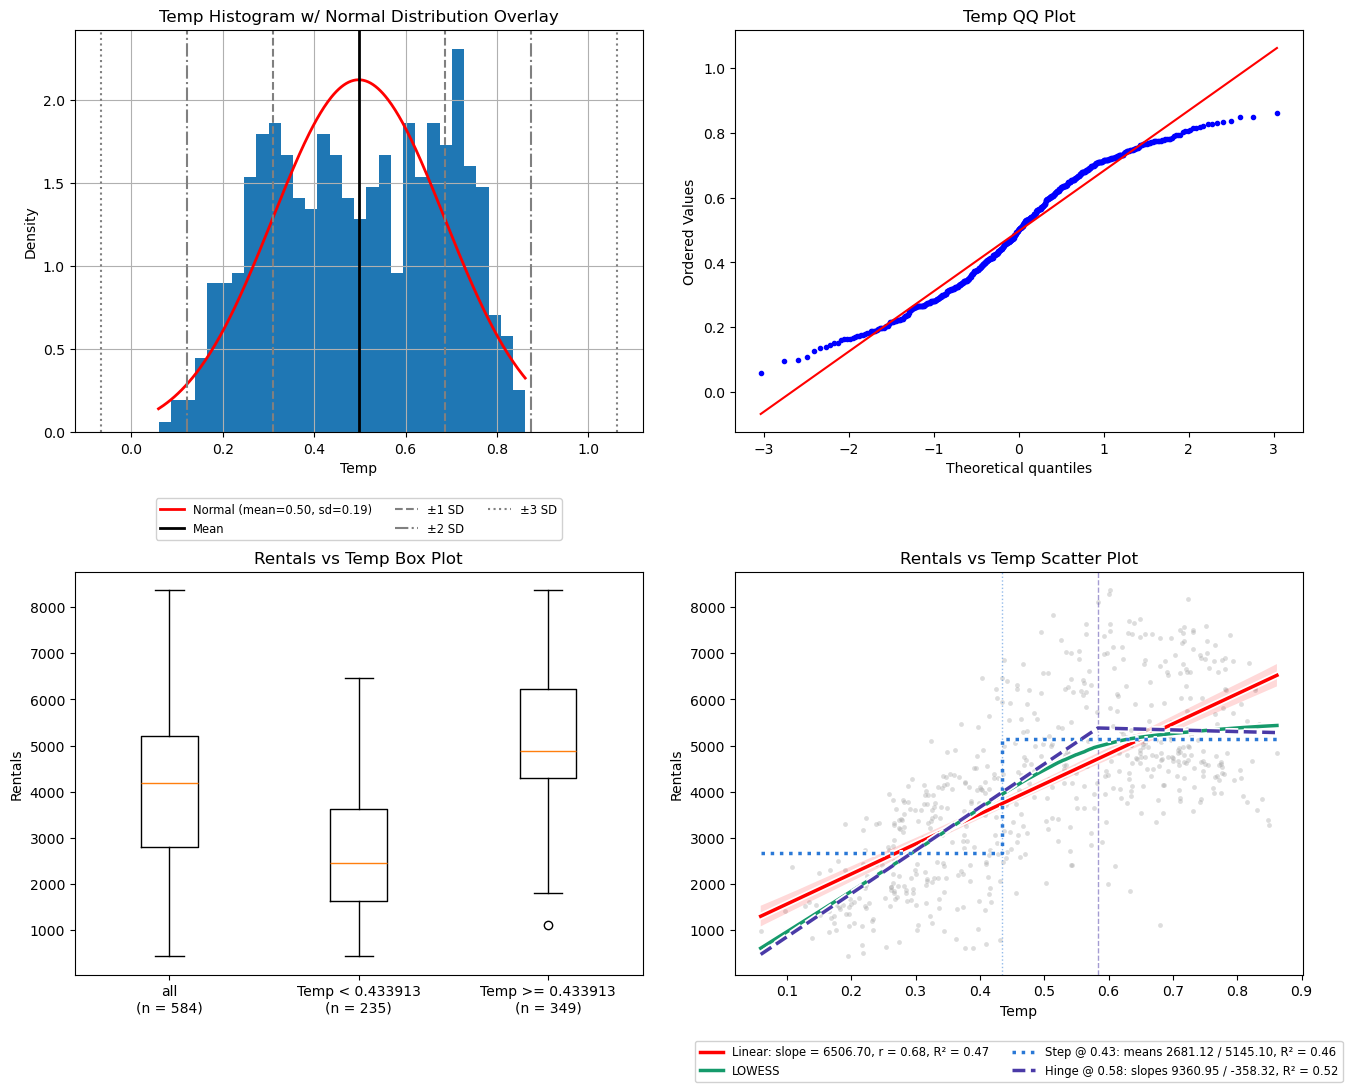

In [14]:
PLOTTING.single_feature_plots(df=temp_df, feature=temp_col, target=TARGET, threshold="auto");

#### Intervention A vs Target

In [15]:
temp_results["A"] = PIPELINES.evaluate_pipeline(
	Pipeline([("model", LinearRegression())]),
	X=temp_X, y=temp_y, folds=temp_folds,
)
display(SCORING.results_df({k: temp_results[k] for k in ["A"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
A,1308.145,67.541,1064.209,52.594,0.456,0.055,0.0,NaN,NaN,NaN,baseline,20


### Intervention B | Flat top (low-side hinge alone)

**What it targets**
In Q2B's scatter plot, Rentals vs Temp is not a straight line. LOWESS climbs steeply up to about 0.6 and is flat or nearly flat above it. A LinearRegression on the raw value can only fit one slope for the whole range, so it has to compromise: too shallow for the low end and too steep for the top, where it predicts Rentals differences between rows that LOWESS says are not there.

**What the intervention does**
Replaces the raw value with one new feature, the distance below a threshold `t`:

`h = max(0, t - x)`

| x | h (t = 0.58) |
|---|---|
| 0.80 | 0 |
| 0.58 | 0 |
| 0.40 | 0.18 |
| 0.10 | 0.48 |

No rows are dropped, and the low values keep their order and spacing. The model becomes `Rentals = a + b·h`:
- **At or above t:** h = 0, so every row gets the same prediction `a`. The top of the range is forced flat.
- **Below t:** the prediction moves in a straight line with the distance below t.

**What it gives up**
Every difference between values above t is erased. That is only safe if those differences carry no information about Rentals. If they do, B removes real signal.

**Variants**
- **B fixed (t = 0.58):** Q2B's hinge threshold, where the two fitted segments meet. Q2B found it by searching all the train rows, including the rows each fold later validates on, so this variant can look optimistic.
- **B nested:** t is searched from 0.05 to 0.95 inside each training fold (inner 4-fold CV, at least 5% of the rows on each side of t), so the validation rows never influence it. This is the honest estimate, and the thresholds it picks show where the data place it.

**Hypothesis**
If Rentals stop responding to Temp above t, forcing the top flat removes the slope the raw line was wrongly fitting there, and B beats A by more than the noise threshold. If the top of the range still carries signal, B loses to C.

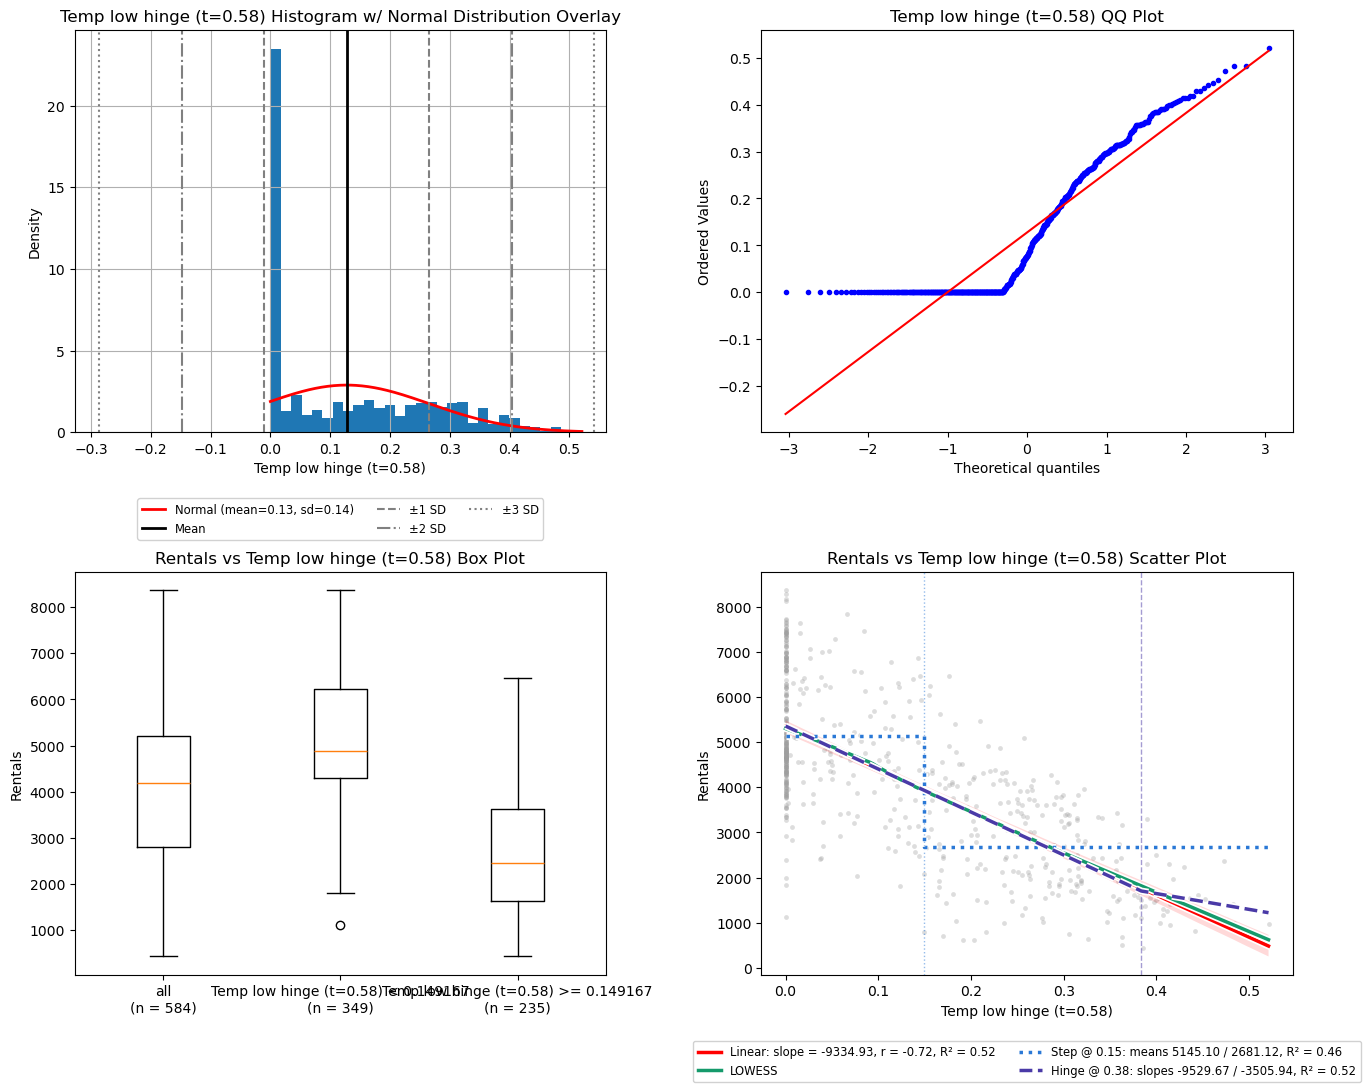

In [16]:
# fit on all temp_df rows, for illustration only (the scores below refit inside each training fold)
temp_b_df = pd.DataFrame(
	{"Temp low hinge (t=0.58)": np.ravel(FEATURES.LowHinge(t=0.58).fit_transform(temp_X)), TARGET: temp_y},
	index=temp_df.index,
)
PLOTTING.single_feature_plots(df=temp_b_df, feature="Temp low hinge (t=0.58)", target=TARGET, threshold="auto");

#### Intervention B vs Target

In [17]:
temp_b_pipeline = Pipeline([("features", FEATURES.LowHinge(t=0.58)), ("model", LinearRegression())])

temp_results["B fixed (t=0.58)"] = PIPELINES.evaluate_pipeline(
	temp_b_pipeline,
	X=temp_X, y=temp_y, folds=temp_folds,
)
temp_results["B nested"] = PIPELINES.evaluate_pipeline(
	FEATURES.nested_threshold(temp_b_pipeline, param="features__t"),
	X=temp_X, y=temp_y, folds=temp_folds, return_estimator=True,
)
display(SCORING.results_df({k: temp_results[k] for k in ["A", "B fixed (t=0.58)", "B nested"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
B fixed (t=0.58),1244.738,55.093,1015.433,39.519,0.508,0.040,-63.406,18.923,-3.351,0.002,candidate,20
B nested,1248.142,54.808,1017.512,40.103,0.505,0.041,-60.003,19.071,-3.146,0.003,candidate,20
A,1308.145,67.541,1064.209,52.594,0.456,0.055,0.000,NaN,NaN,NaN,baseline,20


In [18]:
# threshold picked by the inner search in each of the 20 folds
temp_b_picked = FEATURES.picked_thresholds(temp_results["B nested"]["estimator"], param="features__t")
display(pd.Series(temp_b_picked).value_counts().sort_index().rename_axis("B nested picked t").to_frame("folds"))

,folds
B nested picked t,
0.55,2
0.57,11
0.59,7


### Intervention C | Linear spline (raw + hinge)

**What it targets**
The same bend as B. Unlike B, C does not force the top flat, so it can keep a slope there (up or down) if the data support one.

**What the intervention does**
Keeps the raw value and adds a hinge above `t` as a second feature:

`[x, max(0, x - t)]`

| x | features [x, h] (t = 0.58) |
|---|---|
| 0.10 | [0.10, 0] |
| 0.58 | [0.58, 0] |
| 0.70 | [0.70, 0.12] |
| 0.80 | [0.80, 0.22] |

The model becomes `Rentals = a + b·x + c·max(0, x - t)`, two straight segments joined at t:
- **At or below t:** h = 0, so the prediction is `a + b·x`, a line with slope b.
- **Above t:** h = x - t, so the prediction is `(a - c·t) + (b + c)·x`, a line with slope b + c.

The two segments meet at t, so the prediction has a corner there but no jump. No plot cell, since the feature is two columns.

**What it gives up**
One extra coefficient, which can fit noise in the training folds. If the bend is not real, c ends up near 0 and C reduces to A with an extra parameter.

**Variants**
- **C fixed (t = 0.58):** Q2B's hinge threshold. Q2B found it by searching all the train rows, including the rows each fold later validates on, so this variant can look optimistic.
- **C nested:** t is searched from 0.05 to 0.95 inside each training fold (inner 4-fold CV, at least 5% of the rows on each side of t), so the validation rows never influence it. This is the honest estimate, and the thresholds it picks show where the data place it.

**Hypothesis**
If the top is truly flat, C has no advantage over B. If Rentals still move with Temp above t, C beats B, because it keeps the slope that B erases. If there is no bend, C ties with A.

#### Intervention C vs Target

In [19]:
temp_c_pipeline = Pipeline([("features", FEATURES.HighHinge(t=0.58, keep_raw=True)), ("model", LinearRegression())])

temp_results["C fixed (t=0.58)"] = PIPELINES.evaluate_pipeline(
	temp_c_pipeline,
	X=temp_X, y=temp_y, folds=temp_folds,
)
temp_results["C nested"] = PIPELINES.evaluate_pipeline(
	FEATURES.nested_threshold(temp_c_pipeline, param="features__t"),
	X=temp_X, y=temp_y, folds=temp_folds, return_estimator=True,
)
display(SCORING.results_df({k: temp_results[k] for k in ["A", "C fixed (t=0.58)", "C nested"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
C fixed (t=0.58),1249.222,55.524,1018.411,40.565,0.505,0.042,-58.923,20.747,-2.840,0.005,candidate,20
C nested,1252.084,54.325,1020.290,40.028,0.502,0.042,-56.060,21.863,-2.564,0.009,candidate,20
A,1308.145,67.541,1064.209,52.594,0.456,0.055,0.000,NaN,NaN,NaN,baseline,20


In [20]:
# threshold picked by the inner search in each of the 20 folds
temp_c_picked = FEATURES.picked_thresholds(temp_results["C nested"]["estimator"], param="features__t")
display(pd.Series(temp_c_picked).value_counts().sort_index().rename_axis("C nested picked t").to_frame("folds"))

,folds
C nested picked t,
0.55,2
0.57,10
0.59,6
0.61,2


### Intervention D | Raw + squared term

**What it targets**
The same rise then flatten shape as B and C, but with a smooth curve and no threshold to pick. Q2B listed a squared term as the alternative to a hinge.

**What the intervention does**
Keeps the raw value and adds its square as a second feature (`PolynomialFeatures(degree=2)`):

`[x, x²]`

| x | features [x, x²] |
|---|---|
| 0.10 | [0.10, 0.01] |
| 0.40 | [0.40, 0.16] |
| 0.60 | [0.60, 0.36] |
| 0.80 | [0.80, 0.64] |

The model becomes `Rentals = a + b·x + c·x²`, a parabola. With a negative c it rises quickly at first, slows down, and levels off. No plot cell, since the feature is two columns.

**What it gives up**
One extra coefficient, and a fixed shape: a parabola bends by the same amount everywhere and is symmetric around its peak, so it cannot be steep and then flat. Once it levels off it has to turn down.

**Hypothesis**
If the bend is gradual, D matches C without needing a threshold. If the bend is a sharp corner followed by a flat top, B or C fit it better than D.

#### Intervention D vs Target

In [21]:
temp_results["D"] = PIPELINES.evaluate_pipeline(
	Pipeline([("features", PolynomialFeatures(degree=2, include_bias=False)), ("model", LinearRegression())]),
	X=temp_X, y=temp_y, folds=temp_folds,
)
display(SCORING.results_df({k: temp_results[k] for k in ["A", "D"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
D,1262.853,60.487,1021.827,46.392,0.494,0.041,-45.292,15.839,-2.86,0.005,candidate,20
A,1308.145,67.541,1064.209,52.594,0.456,0.055,0.000,NaN,NaN,NaN,baseline,20


### Intervention E | Flexible spline ceiling

**What it targets**
Not one specific shape. A ceiling: how much of Rentals any smooth single-column shape of Temp can explain. B to D each force one shape. E tells whether those shapes leave signal behind.

**What the intervention does**
Replaces the raw value with a cubic spline basis (`SplineTransformer`, degree 3). The range of x is cut into equal-width pieces at `n_knots` knots, and the LR fits a separate cubic curve on each piece, joined smoothly at the knots. With enough knots it can follow a bend, a flat region and a steep region at the same time, wherever the data put them.

The number of knots is searched from [3, 4, 5, 6, 8, 10] inside each training fold (inner 4-fold CV), the same way the nested thresholds are (without the 5% guard, which only applies to thresholds), so the validation rows never influence it. Values outside the training range are extended in a straight line. No plot cell, since the feature is several columns.

**What it gives up**
Interpretability and simplicity: several coefficients instead of one or two, and no single threshold to carry forward. More knots can also fit noise, which the inner search is there to limit.

**Hypothesis**
- **If E scores about the same as the best of B to D:** the simple shapes already capture the signal, and the simpler one is carried forward.
- **If E is clearly better:** the simple shapes are missing part of the relationship.

#### Intervention E vs Target

In [22]:
temp_e_pipeline = Pipeline([("features", SplineTransformer(degree=3, extrapolation="linear")), ("model", LinearRegression())])

temp_results["E nested"] = PIPELINES.evaluate_pipeline(
	FEATURES.nested_threshold(temp_e_pipeline, param="features__n_knots", grid=[3, 4, 5, 6, 8, 10], min_group_frac=None),
	X=temp_X, y=temp_y, folds=temp_folds, return_estimator=True,
)
display(SCORING.results_df({k: temp_results[k] for k in ["A", "E nested"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
E nested,1255.175,54.919,1029.998,40.783,0.499,0.046,-52.97,23.34,-2.269,0.018,candidate,20
A,1308.145,67.541,1064.209,52.594,0.456,0.055,0.00,NaN,NaN,NaN,baseline,20


In [23]:
# number of knots picked by the inner search in each of the 20 folds
temp_e_picked = FEATURES.picked_thresholds(temp_results["E nested"]["estimator"], param="features__n_knots")
display(pd.Series(temp_e_picked).astype(int).value_counts().sort_index().rename_axis("E nested picked n_knots").to_frame("folds"))

,folds
E nested picked n_knots,
3,8
4,3
6,6
8,3


### Comparison

In [24]:
display(SCORING.results_df(temp_results, baseline="A", holm=True))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,p (Holm),verdict,folds
intervention,,,,,,,,,,,,,
B fixed (t=0.58),1244.738,55.093,1015.433,39.519,0.508,0.040,-63.406,18.923,-3.351,0.002,0.010,significant,20
B nested,1248.142,54.808,1017.512,40.103,0.505,0.041,-60.003,19.071,-3.146,0.003,0.013,significant,20
C fixed (t=0.58),1249.222,55.524,1018.411,40.565,0.505,0.042,-58.923,20.747,-2.840,0.005,0.020,significant,20
C nested,1252.084,54.325,1020.290,40.028,0.502,0.042,-56.060,21.863,-2.564,0.009,0.020,significant,20
E nested,1255.175,54.919,1029.998,40.783,0.499,0.046,-52.970,23.340,-2.269,0.018,0.020,significant,20
D,1262.853,60.487,1021.827,46.392,0.494,0.041,-45.292,15.839,-2.860,0.005,0.020,significant,20
A,1308.145,67.541,1064.209,52.594,0.456,0.055,0.000,NaN,NaN,NaN,NaN,baseline,20


## Temp Results

- **Every intervention is significant.** After the Holm adjustment across the 6 comparisons with A, every `p (Holm)` is between 0.010 and 0.020. A scores rmse 1308.145 (r2 0.456), and the gains run from -45.292 (D) to -63.406 (B fixed).
- **The flat top scores best.** B fixed (t = 0.58) has rmse 1244.738 and r2 0.508, and B nested confirms it without seeing the validation rows (rmse 1248.142, Δ -60.003, Δ / SE -3.146).
- **The bend location is stable.** B nested picked t between 0.55 and 0.59 in all 20 folds (0.57 in 11), and C nested between 0.55 and 0.61. Both sit next to Q2B's 0.58.
- **Keeping a slope above t does not help.** C scores slightly behind B in both variants (1249.222 vs 1244.738 fixed, 1252.084 vs 1248.142 nested), so Rentals do not move with Temp above the bend.
- **The squared term gains the least** (D, rmse 1262.853, Δ -45.292): the bend is closer to a corner than to a parabola.
- **The spline ceiling is not above the simple shapes** (E nested, rmse 1255.175, behind both B and C), so they leave nothing behind.

#### Carry forward

- **B (flat top, `max(0, t - x)` alone)** as the main candidate, with t near 0.57 or 0.58 (nested picks 0.55 to 0.59).
- **C (raw + hinge)** as the alternative, to check whether the slope above t matters once other attributes are in the model.
- **Drop:** D and E.
- Temp and FeelsLike are redundant (r = 0.997), so only one of the two carries forward. See FeelsLike Results.

## FeelsLike

**What Q2B found**
- **Strong positive relationship with Rentals:** r = 0.69 (linear R² 0.48).
- **Rises, then flattens.** LOWESS climbs steeply up to about 0.6 and is flat or nearly flat above it. The hinge at 0.60 has slopes 9665.32 / -3086.80 and lifts R² to 0.53.
- The hinge turns downward above 0.60, which LOWESS does not follow (it stays flat). B vs C tests whether that downturn is real.
- **Roughly symmetric with no outliers,** so there is no skew or outlier treatment to test.

**What is tested**
- **A:** raw (baseline).
- **B:** flat top, the low-side hinge alone.
- **C:** linear spline, raw + hinge.
- **D:** raw + squared term.
- **E:** flexible spline ceiling.

In [25]:
feels_col = "FeelsLike"
feels_df = train_df[[feels_col, TARGET]]
feels_X = feels_df[[feels_col]]
feels_y = feels_df[TARGET]

feels_folds = PIPELINES.make_folds(feels_X, seeds=SEEDS)
feels_results = {}

print(f"rows used: {len(feels_df)} of {len(train_df)}")
print(f"folds: {len(feels_folds)}")

rows used: 584 of 584
folds: 20


### Intervention A | Baseline (raw)

**What it targets**
Nothing. A is the reference that every other intervention is measured against.

**What the intervention does**
The LR gets the raw FeelsLike value `x` with no transform and fits one straight line:

`Rentals = a + b·x`

The plot below is Q2B's view of the raw column, kept here for side-by-side reference with the transformed features further down.

**What it gives up**
Nothing in the column is changed, but the line cannot bend. It has one slope for the whole range, so it keeps rising across the top of the range, where LOWESS in Q2B is flat.

**Hypothesis**
A sets the bar. Every other intervention must beat A by more than the noise threshold to be worth carrying forward. Otherwise A is kept as the simpler model.

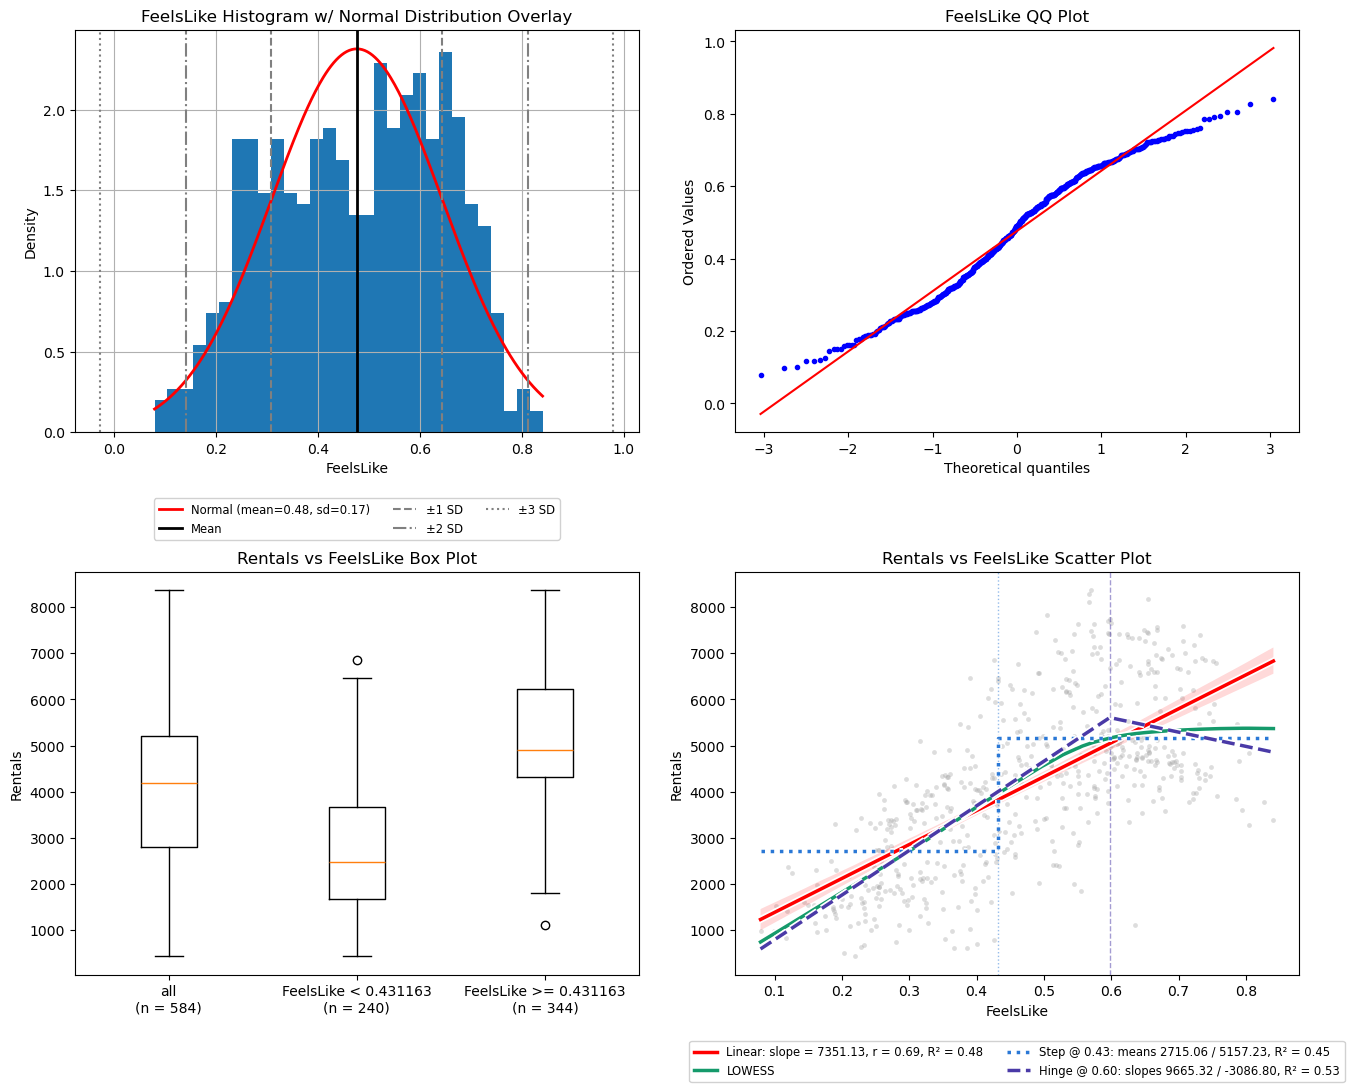

In [26]:
PLOTTING.single_feature_plots(df=feels_df, feature=feels_col, target=TARGET, threshold="auto");

#### Intervention A vs Target

In [27]:
feels_results["A"] = PIPELINES.evaluate_pipeline(
	Pipeline([("model", LinearRegression())]),
	X=feels_X, y=feels_y, folds=feels_folds,
)
display(SCORING.results_df({k: feels_results[k] for k in ["A"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
A,1300.124,66.982,1049.057,53.282,0.463,0.054,0.0,NaN,NaN,NaN,baseline,20


### Intervention B | Flat top (low-side hinge alone)

**What it targets**
In Q2B's scatter plot, Rentals vs FeelsLike is not a straight line. LOWESS climbs steeply up to about 0.6 and is flat or nearly flat above it. A LinearRegression on the raw value can only fit one slope for the whole range, so it has to compromise: too shallow for the low end and too steep for the top, where it predicts Rentals differences between rows that LOWESS says are not there.

**What the intervention does**
Replaces the raw value with one new feature, the distance below a threshold `t`:

`h = max(0, t - x)`

| x | h (t = 0.60) |
|---|---|
| 0.80 | 0 |
| 0.60 | 0 |
| 0.40 | 0.20 |
| 0.10 | 0.50 |

No rows are dropped, and the low values keep their order and spacing. The model becomes `Rentals = a + b·h`:
- **At or above t:** h = 0, so every row gets the same prediction `a`. The top of the range is forced flat.
- **Below t:** the prediction moves in a straight line with the distance below t.

**What it gives up**
Every difference between values above t is erased. That is only safe if those differences carry no information about Rentals. If they do, B removes real signal.

**Variants**
- **B fixed (t = 0.60):** Q2B's hinge threshold, where the two fitted segments meet. Q2B found it by searching all the train rows, including the rows each fold later validates on, so this variant can look optimistic.
- **B nested:** t is searched from 0.05 to 0.95 inside each training fold (inner 4-fold CV, at least 5% of the rows on each side of t), so the validation rows never influence it. This is the honest estimate, and the thresholds it picks show where the data place it.

**Hypothesis**
If Rentals stop responding to FeelsLike above t, forcing the top flat removes the slope the raw line was wrongly fitting there, and B beats A by more than the noise threshold. If the top of the range still carries signal, B loses to C.

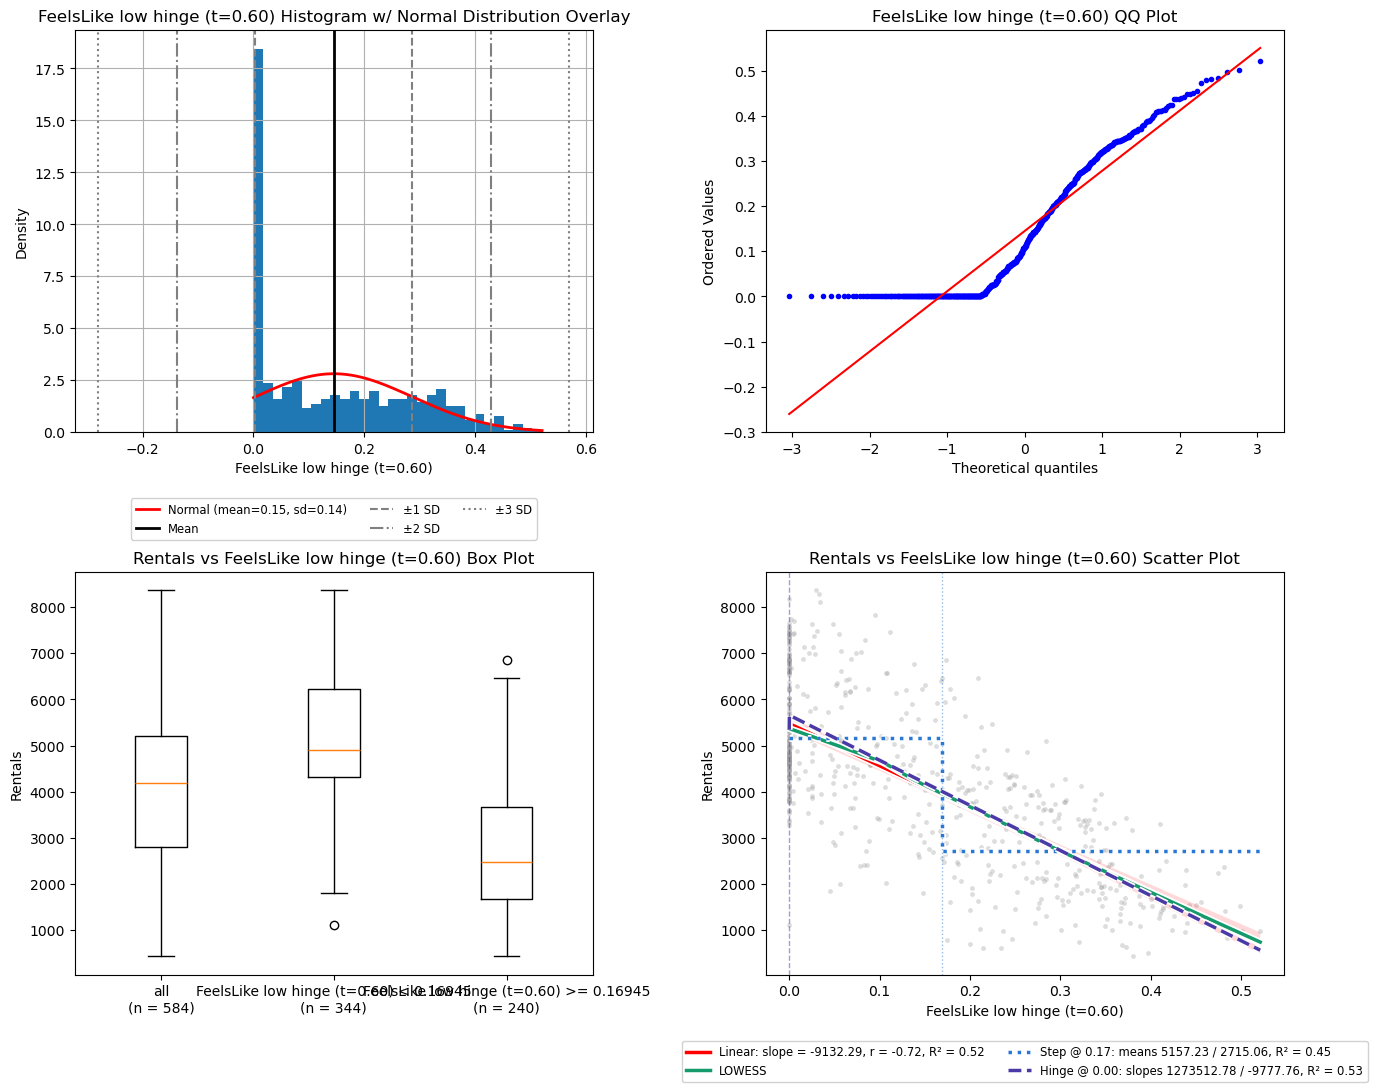

In [28]:
# fit on all feels_df rows, for illustration only (the scores below refit inside each training fold)
feels_b_df = pd.DataFrame(
	{"FeelsLike low hinge (t=0.60)": np.ravel(FEATURES.LowHinge(t=0.60).fit_transform(feels_X)), TARGET: feels_y},
	index=feels_df.index,
)
PLOTTING.single_feature_plots(df=feels_b_df, feature="FeelsLike low hinge (t=0.60)", target=TARGET, threshold="auto");

#### Intervention B vs Target

In [29]:
feels_b_pipeline = Pipeline([("features", FEATURES.LowHinge(t=0.60)), ("model", LinearRegression())])

feels_results["B fixed (t=0.60)"] = PIPELINES.evaluate_pipeline(
	feels_b_pipeline,
	X=feels_X, y=feels_y, folds=feels_folds,
)
feels_results["B nested"] = PIPELINES.evaluate_pipeline(
	FEATURES.nested_threshold(feels_b_pipeline, param="features__t"),
	X=feels_X, y=feels_y, folds=feels_folds, return_estimator=True,
)
display(SCORING.results_df({k: feels_results[k] for k in ["A", "B fixed (t=0.60)", "B nested"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
B fixed (t=0.60),1239.640,57.367,1016.686,41.616,0.512,0.044,-60.483,12.765,-4.738,0.0,candidate,20
B nested,1239.809,56.709,1013.619,42.057,0.512,0.042,-60.315,15.128,-3.987,0.0,candidate,20
A,1300.124,66.982,1049.057,53.282,0.463,0.054,0.000,NaN,NaN,NaN,baseline,20


In [30]:
# threshold picked by the inner search in each of the 20 folds
feels_b_picked = FEATURES.picked_thresholds(feels_results["B nested"]["estimator"], param="features__t")
display(pd.Series(feels_b_picked).value_counts().sort_index().rename_axis("B nested picked t").to_frame("folds"))

,folds
B nested picked t,
0.57,12
0.59,8


### Intervention C | Linear spline (raw + hinge)

**What it targets**
The same bend as B. Unlike B, C does not force the top flat, so it can keep a slope there (up or down) if the data support one.

**What the intervention does**
Keeps the raw value and adds a hinge above `t` as a second feature:

`[x, max(0, x - t)]`

| x | features [x, h] (t = 0.60) |
|---|---|
| 0.10 | [0.10, 0] |
| 0.60 | [0.60, 0] |
| 0.70 | [0.70, 0.10] |
| 0.80 | [0.80, 0.20] |

The model becomes `Rentals = a + b·x + c·max(0, x - t)`, two straight segments joined at t:
- **At or below t:** h = 0, so the prediction is `a + b·x`, a line with slope b.
- **Above t:** h = x - t, so the prediction is `(a - c·t) + (b + c)·x`, a line with slope b + c.

The two segments meet at t, so the prediction has a corner there but no jump. No plot cell, since the feature is two columns.

**What it gives up**
One extra coefficient, which can fit noise in the training folds. If the bend is not real, c ends up near 0 and C reduces to A with an extra parameter.

**Variants**
- **C fixed (t = 0.60):** Q2B's hinge threshold. Q2B found it by searching all the train rows, including the rows each fold later validates on, so this variant can look optimistic.
- **C nested:** t is searched from 0.05 to 0.95 inside each training fold (inner 4-fold CV, at least 5% of the rows on each side of t), so the validation rows never influence it. This is the honest estimate, and the thresholds it picks show where the data place it.

**Hypothesis**
If the downturn above t is real, C beats B. If the top is flat, as LOWESS shows, B ties with C using one feature fewer. If there is no bend, C ties with A.

#### Intervention C vs Target

In [31]:
feels_c_pipeline = Pipeline([("features", FEATURES.HighHinge(t=0.60, keep_raw=True)), ("model", LinearRegression())])

feels_results["C fixed (t=0.60)"] = PIPELINES.evaluate_pipeline(
	feels_c_pipeline,
	X=feels_X, y=feels_y, folds=feels_folds,
)
feels_results["C nested"] = PIPELINES.evaluate_pipeline(
	FEATURES.nested_threshold(feels_c_pipeline, param="features__t"),
	X=feels_X, y=feels_y, folds=feels_folds, return_estimator=True,
)
display(SCORING.results_df({k: feels_results[k] for k in ["A", "C fixed (t=0.60)", "C nested"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
C fixed (t=0.60),1237.651,56.282,1016.660,39.762,0.514,0.043,-62.473,20.242,-3.086,0.003,candidate,20
C nested,1243.430,55.613,1020.583,40.236,0.509,0.045,-56.694,21.450,-2.643,0.008,candidate,20
A,1300.124,66.982,1049.057,53.282,0.463,0.054,0.000,NaN,NaN,NaN,baseline,20


In [32]:
# threshold picked by the inner search in each of the 20 folds
feels_c_picked = FEATURES.picked_thresholds(feels_results["C nested"]["estimator"], param="features__t")
display(pd.Series(feels_c_picked).value_counts().sort_index().rename_axis("C nested picked t").to_frame("folds"))

,folds
C nested picked t,
0.57,2
0.59,9
0.61,6
0.63,1
0.65,1
0.67,1


### Intervention D | Raw + squared term

**What it targets**
The same rise then flatten shape as B and C, but with a smooth curve and no threshold to pick. Q2B listed a squared term as the alternative to a hinge.

**What the intervention does**
Keeps the raw value and adds its square as a second feature (`PolynomialFeatures(degree=2)`):

`[x, x²]`

| x | features [x, x²] |
|---|---|
| 0.10 | [0.10, 0.01] |
| 0.40 | [0.40, 0.16] |
| 0.60 | [0.60, 0.36] |
| 0.80 | [0.80, 0.64] |

The model becomes `Rentals = a + b·x + c·x²`, a parabola. With a negative c it rises quickly at first, slows down, and levels off. No plot cell, since the feature is two columns.

**What it gives up**
One extra coefficient, and a fixed shape: a parabola bends by the same amount everywhere and is symmetric around its peak, so it cannot be steep and then flat. Once it levels off it has to turn down.

**Hypothesis**
If the bend is gradual, D matches C without needing a threshold. If the bend is a sharp corner followed by a flat top, B or C fit it better than D.

#### Intervention D vs Target

In [33]:
feels_results["D"] = PIPELINES.evaluate_pipeline(
	Pipeline([("features", PolynomialFeatures(degree=2, include_bias=False)), ("model", LinearRegression())]),
	X=feels_X, y=feels_y, folds=feels_folds,
)
display(SCORING.results_df({k: feels_results[k] for k in ["A", "D"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
D,1261.542,62.220,1018.241,49.204,0.495,0.041,-38.582,14.042,-2.748,0.006,candidate,20
A,1300.124,66.982,1049.057,53.282,0.463,0.054,0.000,NaN,NaN,NaN,baseline,20


### Intervention E | Flexible spline ceiling

**What it targets**
Not one specific shape. A ceiling: how much of Rentals any smooth single-column shape of FeelsLike can explain. B to D each force one shape. E tells whether those shapes leave signal behind.

**What the intervention does**
Replaces the raw value with a cubic spline basis (`SplineTransformer`, degree 3). The range of x is cut into equal-width pieces at `n_knots` knots, and the LR fits a separate cubic curve on each piece, joined smoothly at the knots. With enough knots it can follow a bend, a flat region and a steep region at the same time, wherever the data put them.

The number of knots is searched from [3, 4, 5, 6, 8, 10] inside each training fold (inner 4-fold CV), the same way the nested thresholds are (without the 5% guard, which only applies to thresholds), so the validation rows never influence it. Values outside the training range are extended in a straight line. No plot cell, since the feature is several columns.

**What it gives up**
Interpretability and simplicity: several coefficients instead of one or two, and no single threshold to carry forward. More knots can also fit noise, which the inner search is there to limit.

**Hypothesis**
- **If E scores about the same as the best of B to D:** the simple shapes already capture the signal, and the simpler one is carried forward.
- **If E is clearly better:** the simple shapes are missing part of the relationship.

#### Intervention E vs Target

In [34]:
feels_e_pipeline = Pipeline([("features", SplineTransformer(degree=3, extrapolation="linear")), ("model", LinearRegression())])

feels_results["E nested"] = PIPELINES.evaluate_pipeline(
	FEATURES.nested_threshold(feels_e_pipeline, param="features__n_knots", grid=[3, 4, 5, 6, 8, 10], min_group_frac=None),
	X=feels_X, y=feels_y, folds=feels_folds, return_estimator=True,
)
display(SCORING.results_df({k: feels_results[k] for k in ["A", "E nested"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
E nested,1238.527,54.134,1018.139,36.693,0.513,0.045,-61.597,21.863,-2.817,0.005,candidate,20
A,1300.124,66.982,1049.057,53.282,0.463,0.054,0.000,NaN,NaN,NaN,baseline,20


In [35]:
# number of knots picked by the inner search in each of the 20 folds
feels_e_picked = FEATURES.picked_thresholds(feels_results["E nested"]["estimator"], param="features__n_knots")
display(pd.Series(feels_e_picked).astype(int).value_counts().sort_index().rename_axis("E nested picked n_knots").to_frame("folds"))

,folds
E nested picked n_knots,
3,12
4,5
6,1
8,1
10,1


### Comparison

In [36]:
display(SCORING.results_df(feels_results, baseline="A", holm=True))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,p (Holm),verdict,folds
intervention,,,,,,,,,,,,,
C fixed (t=0.60),1237.651,56.282,1016.660,39.762,0.514,0.043,-62.473,20.242,-3.086,0.003,0.012,significant,20
E nested,1238.527,54.134,1018.139,36.693,0.513,0.045,-61.597,21.863,-2.817,0.005,0.016,significant,20
B fixed (t=0.60),1239.640,57.367,1016.686,41.616,0.512,0.044,-60.483,12.765,-4.738,0.000,0.000,significant,20
B nested,1239.809,56.709,1013.619,42.057,0.512,0.042,-60.315,15.128,-3.987,0.000,0.002,significant,20
C nested,1243.430,55.613,1020.583,40.236,0.509,0.045,-56.694,21.450,-2.643,0.008,0.016,significant,20
D,1261.542,62.220,1018.241,49.204,0.495,0.041,-38.582,14.042,-2.748,0.006,0.016,significant,20
A,1300.124,66.982,1049.057,53.282,0.463,0.054,0.000,NaN,NaN,NaN,NaN,baseline,20


## FeelsLike Results

- **Every intervention is significant.** After the Holm adjustment across the 6 comparisons with A, every `p (Holm)` is 0.016 or less. A scores rmse 1300.124 (r2 0.463), slightly ahead of Temp's A (1308.145, r2 0.456).
- **Five shapes finish within 6 rmse of each other:** C fixed (1237.651, Δ -62.473), E nested (1238.527), B fixed (1239.640), B nested (1239.809) and C nested (1243.430). Only D (the squared term) trails, at 1261.542 (Δ -38.582).
- **The downturn above t is not supported.** C fixed is 2 rmse ahead of B fixed (1237.651 vs 1239.640), but C nested is behind B nested (1243.430 vs 1239.809). The hinge's negative second slope in Q2B does not hold up once t is searched inside the folds, which agrees with LOWESS staying flat.
- **The flat top is the most consistent gain.** B fixed has the strongest Δ / SE (-4.738) and B nested the next (-3.987). B nested picked t = 0.57 in 12 folds and 0.59 in 8, while C nested spread from 0.57 to 0.67.
- **The spline ceiling matches the simple shapes** (E nested 1238.527 vs B nested 1239.809), picking 3 knots in 12 of 20 folds, so the flat top leaves nothing behind.

#### Carry forward

- **B (flat top, `max(0, t - x)` alone)** as the main candidate, with t near 0.57 to 0.60.
- **C (raw + hinge)** as the alternative.
- **Drop:** D and E.
- **FeelsLike or Temp, not both.** FeelsLike is slightly ahead in A (rmse 1300.124 vs 1308.145) and in the best shape (1237.651 vs 1244.738), so it is the first choice. The gap between the two attributes was not tested, so Temp stays as the fallback.

## Humidity

**What Q2B found**
- **Weak negative relationship with Rentals:** r = -0.128 (linear R² 0.02).
- **Only matters once it is high.** LOWESS rises gently up to about 0.65, then falls steeply. The hinge at 0.70 flips the slope from 1641.73 to -9191.70 (R² 0.07), and the step at 0.78 gives means of 4335.63 / 3154.44 (R² 0.06).
- **One low outlier:** a single value of exactly 0.0, below the 0.172 fence.
- **Roughly symmetric,** so there is no skew treatment to test.

**What is tested**
- **A:** raw (baseline).
- **B:** high-side hinge alone.
- **C:** linear spline, raw + hinge.
- **D:** high-value indicator.
- **E:** IQR fence clip, for the 0.0 value.
- **F:** flexible spline ceiling.

In [37]:
hum_col = "Humidity"
hum_df = train_df[[hum_col, TARGET]]
hum_X = hum_df[[hum_col]]
hum_y = hum_df[TARGET]

hum_folds = PIPELINES.make_folds(hum_X, seeds=SEEDS)
hum_results = {}

print(f"rows used: {len(hum_df)} of {len(train_df)}")
print(f"folds: {len(hum_folds)}")

rows used: 584 of 584
folds: 20


### Intervention A | Baseline (raw)

**What it targets**
Nothing. A is the reference that every other intervention is measured against.

**What the intervention does**
The LR gets the raw Humidity value `x` with no transform and fits one straight line:

`Rentals = a + b·x`

The plot below is Q2B's view of the raw column, kept here for side-by-side reference with the transformed features further down.

**What it gives up**
Nothing in the column is changed, but the line cannot bend. It has one slope for the whole range, so it cannot be flat across the low and middle values and steep at the top, which is what LOWESS shows in Q2B.

**Hypothesis**
A sets the bar. Every other intervention must beat A by more than the noise threshold to be worth carrying forward. Otherwise A is kept as the simpler model.

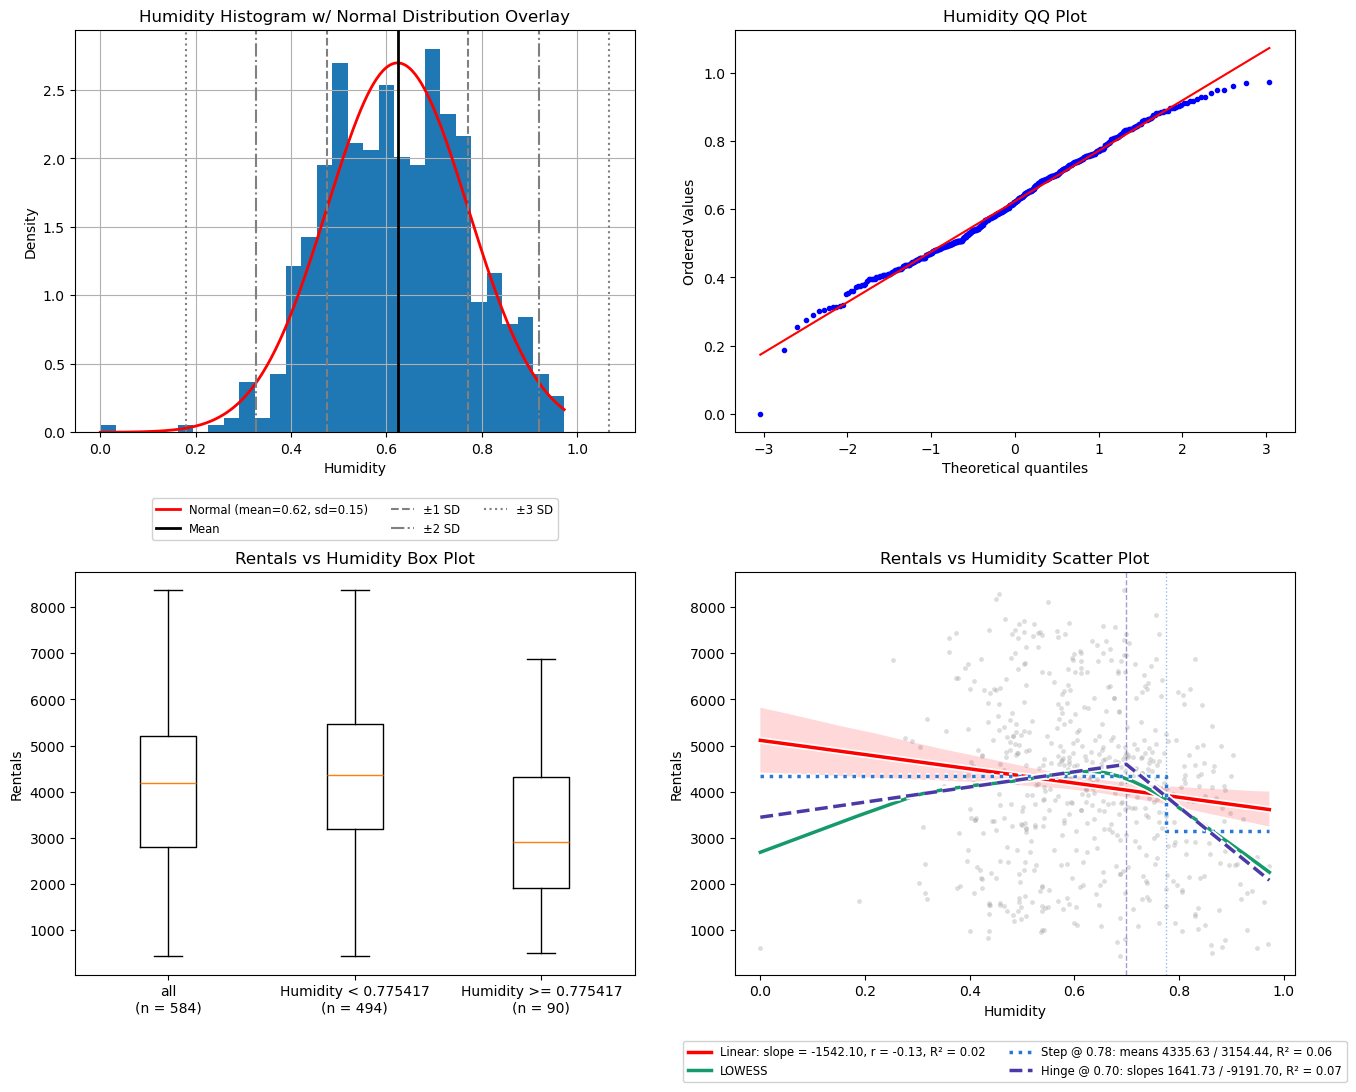

In [38]:
PLOTTING.single_feature_plots(df=hum_df, feature=hum_col, target=TARGET, threshold="auto");

#### Intervention A vs Target

In [39]:
hum_results["A"] = PIPELINES.evaluate_pipeline(
	Pipeline([("model", LinearRegression())]),
	X=hum_X, y=hum_y, folds=hum_folds,
)
display(SCORING.results_df({k: hum_results[k] for k in ["A"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
A,1775.147,114.54,1434.661,113.408,0.005,0.025,0.0,NaN,NaN,NaN,baseline,20


### Intervention B | High-side hinge alone

**What it targets**
In Q2B's scatter plot, Rentals barely move with Humidity until it is high, then fall steeply. A straight line spreads that fall over the whole range, so it is too steep where nothing happens and too shallow where Rentals drop.

**What the intervention does**
Replaces the raw value with one new feature, the distance above a threshold `t`:

`h = max(0, x - t)`

| x | h (t = 0.70) |
|---|---|
| 0.30 | 0 |
| 0.70 | 0 |
| 0.80 | 0.10 |
| 0.95 | 0.25 |

The model becomes `Rentals = a + b·h`:
- **At or below t:** h = 0, so every row gets the same prediction `a`. The low and middle of the range are forced flat.
- **Above t:** the prediction moves in a straight line with the distance above t.

**What it gives up**
Every difference between values below t is erased, including the gentle rise LOWESS shows there.

**Variants**
- **B fixed (t = 0.70):** Q2B's hinge threshold. Q2B found it by searching all the train rows, including the rows each fold later validates on, so this variant can look optimistic.
- **B nested:** t is searched from 0.05 to 0.95 inside each training fold (inner 4-fold CV, at least 5% of the rows on each side of t), so the validation rows never influence it. This is the honest estimate, and the thresholds it picks show where the data place it.

**Hypothesis**
If Rentals only respond to Humidity above t, B beats A by more than the noise threshold. If the gentle rise below t is real, B loses to C.

/opt/homebrew/Caskroom/miniconda/base/envs/homl3/lib/python3.10/site-packages/statsmodels/nonparametric/smoothers_lowess.py:226: RuntimeWarning: invalid value encountered in divide
  res, _ = _lowess(y, x, x, np.ones_like(x),


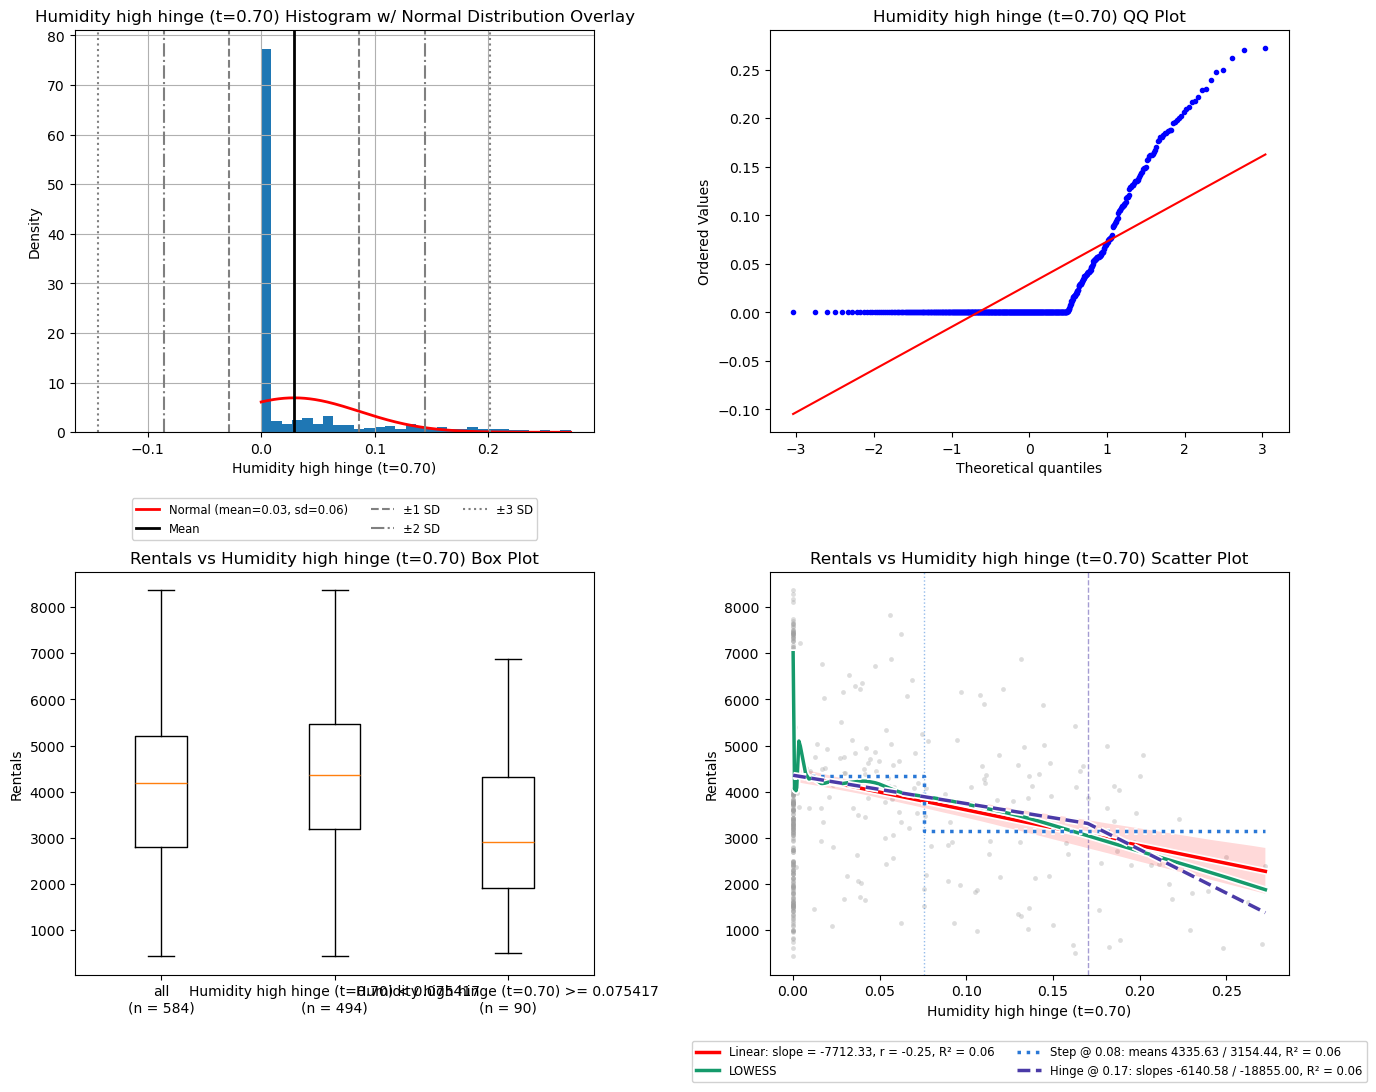

In [40]:
# fit on all hum_df rows, for illustration only (the scores below refit inside each training fold)
hum_b_df = pd.DataFrame(
	{"Humidity high hinge (t=0.70)": np.ravel(FEATURES.HighHinge(t=0.70).fit_transform(hum_X)), TARGET: hum_y},
	index=hum_df.index,
)
PLOTTING.single_feature_plots(df=hum_b_df, feature="Humidity high hinge (t=0.70)", target=TARGET, threshold="auto");

#### Intervention B vs Target

In [41]:
hum_b_pipeline = Pipeline([("features", FEATURES.HighHinge(t=0.70)), ("model", LinearRegression())])

hum_results["B fixed (t=0.70)"] = PIPELINES.evaluate_pipeline(
	hum_b_pipeline,
	X=hum_X, y=hum_y, folds=hum_folds,
)
hum_results["B nested"] = PIPELINES.evaluate_pipeline(
	FEATURES.nested_threshold(hum_b_pipeline, param="features__t"),
	X=hum_X, y=hum_y, folds=hum_folds, return_estimator=True,
)
display(SCORING.results_df({k: hum_results[k] for k in ["A", "B fixed (t=0.70)", "B nested"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
B fixed (t=0.70),1733.959,104.036,1400.725,105.408,0.049,0.031,-41.188,12.091,-3.407,0.001,candidate,20
B nested,1738.048,108.322,1403.277,107.262,0.045,0.029,-37.099,9.584,-3.871,0.001,candidate,20
A,1775.147,114.540,1434.661,113.408,0.005,0.025,0.000,NaN,NaN,NaN,baseline,20


In [42]:
# threshold picked by the inner search in each of the 20 folds
hum_b_picked = FEATURES.picked_thresholds(hum_results["B nested"]["estimator"], param="features__t")
display(pd.Series(hum_b_picked).value_counts().sort_index().rename_axis("B nested picked t").to_frame("folds"))

,folds
B nested picked t,
0.67,1
0.71,3
0.75,12
0.77,2
0.81,1
0.83,1


### Intervention C | Linear spline (raw + hinge)

**What it targets**
The same bend as B. Unlike B, C keeps a slope below t, so it can follow the gentle rise LOWESS shows there.

**What the intervention does**
Keeps the raw value and adds the hinge from B as a second feature:

`[x, max(0, x - t)]`

The model becomes `Rentals = a + b·x + c·max(0, x - t)`, two straight segments joined at t: slope b at or below t and slope b + c above it. No plot cell, since the feature is two columns.

**What it gives up**
One extra coefficient, which can fit noise in the training folds. Very few rows sit below about 0.3 (Q2B), so the slope below t rests mostly on the middle of the range.

**Variants**
- **C fixed (t = 0.70):** Q2B's hinge threshold. Q2B found it by searching all the train rows, including the rows each fold later validates on, so this variant can look optimistic.
- **C nested:** t is searched from 0.05 to 0.95 inside each training fold (inner 4-fold CV, at least 5% of the rows on each side of t), so the validation rows never influence it. This is the honest estimate, and the thresholds it picks show where the data place it.

**Hypothesis**
If both sides of t have a real but different slope, C beats A and also beats B. If the range below t is truly flat, C has no advantage over B.

#### Intervention C vs Target

In [43]:
hum_c_pipeline = Pipeline([("features", FEATURES.HighHinge(t=0.70, keep_raw=True)), ("model", LinearRegression())])

hum_results["C fixed (t=0.70)"] = PIPELINES.evaluate_pipeline(
	hum_c_pipeline,
	X=hum_X, y=hum_y, folds=hum_folds,
)
hum_results["C nested"] = PIPELINES.evaluate_pipeline(
	FEATURES.nested_threshold(hum_c_pipeline, param="features__t"),
	X=hum_X, y=hum_y, folds=hum_folds, return_estimator=True,
)
display(SCORING.results_df({k: hum_results[k] for k in ["A", "C fixed (t=0.70)", "C nested"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
C fixed (t=0.70),1729.986,98.399,1398.149,101.965,0.054,0.031,-45.161,15.551,-2.904,0.005,candidate,20
C nested,1741.357,103.661,1407.480,104.630,0.041,0.030,-33.790,12.023,-2.810,0.006,candidate,20
A,1775.147,114.540,1434.661,113.408,0.005,0.025,0.000,NaN,NaN,NaN,baseline,20


In [44]:
# threshold picked by the inner search in each of the 20 folds
hum_c_picked = FEATURES.picked_thresholds(hum_results["C nested"]["estimator"], param="features__t")
display(pd.Series(hum_c_picked).value_counts().sort_index().rename_axis("C nested picked t").to_frame("folds"))

,folds
C nested picked t,
0.61,1
0.65,1
0.67,3
0.69,6
0.71,3
0.73,3
0.75,1
0.81,1
0.83,1


### Intervention D | High-value indicator

**What it targets**
Q2B's box plot showed a level difference in Rentals between the rows below the step threshold and the rows at or above it. D tests whether that split alone carries the signal.

**What the intervention does**
Replaces the raw value with one binary feature:

`i = 1 if x < t else 0`

| x | i (t = 0.78) |
|---|---|
| 0.30 | 1 |
| 0.70 | 1 |
| 0.78 | 0 |
| 0.95 | 0 |

The model becomes `Rentals = a + b·i`, which predicts one mean per side: `a` for the rows at or above t and `a + b` for the rows below it. No plot cell, since the feature is binary.

**What it gives up**
All variation within each side is erased: a row at 0.80 gets the same prediction as a row at 0.95. The change at t is a hard jump.

**Variants**
- **D fixed (t = 0.78):** Q2B's step threshold. Q2B found it by searching all the train rows, including the rows each fold later validates on, so this variant can look optimistic.
- **D nested:** t is searched from 0.05 to 0.95 inside each training fold (inner 4-fold CV, at least 5% of the rows on each side of t), so the validation rows never influence it. This is the honest estimate, and the thresholds it picks show where the data place it.

**Hypothesis**
If most of the signal is just "high humidity or not", D matches B with a simpler shape. If Rentals keep falling as Humidity rises above t, D loses to B.

#### Intervention D vs Target

In [45]:
hum_d_pipeline = Pipeline([("features", FEATURES.Indicator(t=0.78)), ("model", LinearRegression())])

hum_results["D fixed (t=0.78)"] = PIPELINES.evaluate_pipeline(
	hum_d_pipeline,
	X=hum_X, y=hum_y, folds=hum_folds,
)
hum_results["D nested"] = PIPELINES.evaluate_pipeline(
	FEATURES.nested_threshold(hum_d_pipeline, param="features__t"),
	X=hum_X, y=hum_y, folds=hum_folds, return_estimator=True,
)
display(SCORING.results_df({k: hum_results[k] for k in ["A", "D fixed (t=0.78)", "D nested"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
D fixed (t=0.78),1744.762,99.443,1414.417,101.447,0.037,0.032,-30.385,14.703,-2.067,0.026,candidate,20
D nested,1755.382,104.869,1420.985,109.652,0.026,0.026,-19.765,10.942,-1.806,0.043,candidate,20
A,1775.147,114.540,1434.661,113.408,0.005,0.025,0.000,NaN,NaN,NaN,baseline,20


In [46]:
# threshold picked by the inner search in each of the 20 folds
hum_d_picked = FEATURES.picked_thresholds(hum_results["D nested"]["estimator"], param="features__t")
display(pd.Series(hum_d_picked).value_counts().sort_index().rename_axis("D nested picked t").to_frame("folds"))

,folds
D nested picked t,
0.77,8
0.79,1
0.83,2
0.85,8
0.87,1


### Intervention E | IQR fence clip (the 0.0 value)

**What it targets**
The single value of exactly 0.0 that Q2B flagged. It is the only outlier in the column, far below the next lowest value.

**What the intervention does**
Clips the raw value to the fences Q1 - 1.5·IQR and Q3 + 1.5·IQR, learned on each training fold. The 0.0 becomes the lower fence value (0.172 on all train rows in Q2B) and every value between the fences is unchanged. The model becomes `Rentals = a + b·clip(x)`.

This replaces the value in place of dropping the row, so every intervention is still validated on the same rows.

**What it gives up**
Almost nothing: one row moves, and it stays the lowest value in the column.

**Hypothesis**
One row out of 584 has little pull on the line, so E is expected to be within noise of A. If E beats A, that single value was distorting the fit.

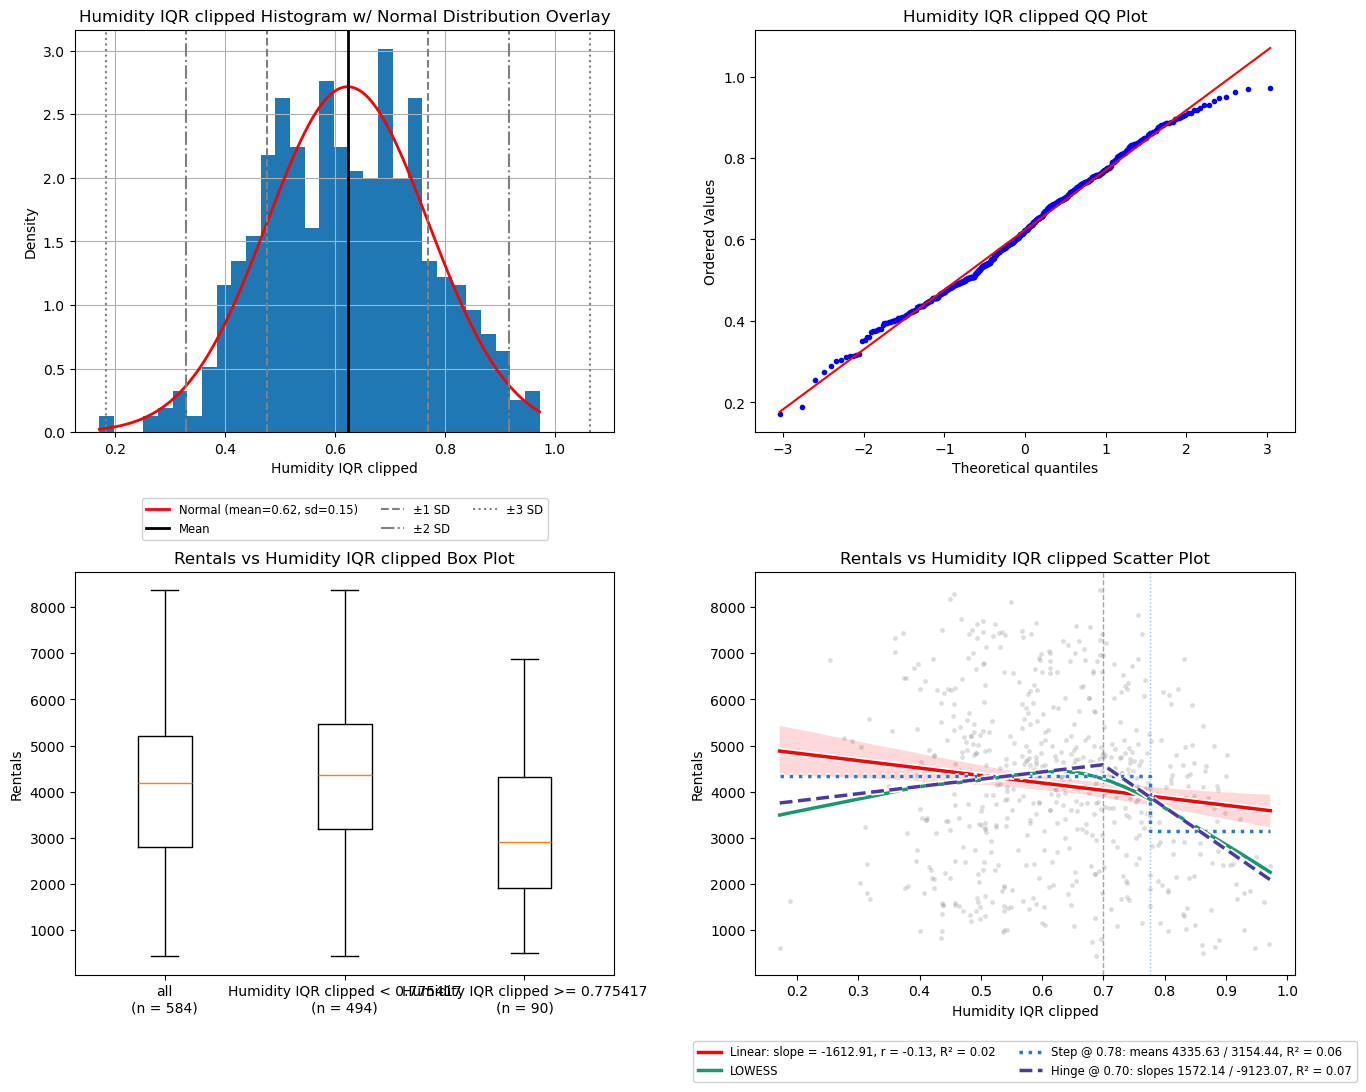

In [47]:
# fit on all hum_df rows, for illustration only (the scores below refit inside each training fold)
hum_e_df = pd.DataFrame(
	{"Humidity IQR clipped": np.ravel(FEATURES.IQRClip().fit_transform(hum_X)), TARGET: hum_y},
	index=hum_df.index,
)
PLOTTING.single_feature_plots(df=hum_e_df, feature="Humidity IQR clipped", target=TARGET, threshold="auto");

#### Intervention E vs Target

In [48]:
hum_results["E"] = PIPELINES.evaluate_pipeline(
	Pipeline([("features", FEATURES.IQRClip()), ("model", LinearRegression())]),
	X=hum_X, y=hum_y, folds=hum_folds,
)
display(SCORING.results_df({k: hum_results[k] for k in ["A", "E"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
E,1773.776,113.413,1434.018,113.124,0.006,0.025,-1.371,1.345,-1.019,0.16,candidate,20
A,1775.147,114.540,1434.661,113.408,0.005,0.025,0.000,NaN,NaN,NaN,baseline,20


### Intervention F | Flexible spline ceiling

**What it targets**
Not one specific shape. A ceiling: how much of Rentals any smooth single-column shape of Humidity can explain. B to D each force one shape. F tells whether those shapes leave signal behind.

**What the intervention does**
Replaces the raw value with a cubic spline basis (`SplineTransformer`, degree 3). The range of x is cut into equal-width pieces at `n_knots` knots, and the LR fits a separate cubic curve on each piece, joined smoothly at the knots. With enough knots it can follow a bend, a flat region and a steep region at the same time, wherever the data put them.

The number of knots is searched from [3, 4, 5, 6, 8, 10] inside each training fold (inner 4-fold CV), the same way the nested thresholds are (without the 5% guard, which only applies to thresholds), so the validation rows never influence it. Values outside the training range are extended in a straight line. No plot cell, since the feature is several columns.

**What it gives up**
Interpretability and simplicity: several coefficients instead of one or two, and no single threshold to carry forward. More knots can also fit noise, which the inner search is there to limit.

**Hypothesis**
- **If F scores about the same as the best of B to D:** the simple shapes already capture the signal, and the simpler one is carried forward.
- **If F is clearly better:** the simple shapes are missing part of the relationship.

#### Intervention F vs Target

In [49]:
hum_f_pipeline = Pipeline([("features", SplineTransformer(degree=3, extrapolation="linear")), ("model", LinearRegression())])

hum_results["F nested"] = PIPELINES.evaluate_pipeline(
	FEATURES.nested_threshold(hum_f_pipeline, param="features__n_knots", grid=[3, 4, 5, 6, 8, 10], min_group_frac=None),
	X=hum_X, y=hum_y, folds=hum_folds, return_estimator=True,
)
display(SCORING.results_df({k: hum_results[k] for k in ["A", "F nested"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
F nested,1739.320,106.378,1399.688,103.698,0.044,0.023,-35.827,15.332,-2.337,0.015,candidate,20
A,1775.147,114.540,1434.661,113.408,0.005,0.025,0.000,NaN,NaN,NaN,baseline,20


In [50]:
# number of knots picked by the inner search in each of the 20 folds
hum_f_picked = FEATURES.picked_thresholds(hum_results["F nested"]["estimator"], param="features__n_knots")
display(pd.Series(hum_f_picked).astype(int).value_counts().sort_index().rename_axis("F nested picked n_knots").to_frame("folds"))

,folds
F nested picked n_knots,
3,13
4,3
5,3
6,1


### Comparison

In [51]:
display(SCORING.results_df(hum_results, baseline="A", holm=True))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,p (Holm),verdict,folds
intervention,,,,,,,,,,,,,
C fixed (t=0.70),1729.986,98.399,1398.149,101.965,0.054,0.031,-45.161,15.551,-2.904,0.005,0.027,significant,20
B fixed (t=0.70),1733.959,104.036,1400.725,105.408,0.049,0.031,-41.188,12.091,-3.407,0.001,0.010,significant,20
B nested,1738.048,108.322,1403.277,107.262,0.045,0.029,-37.099,9.584,-3.871,0.001,0.004,significant,20
F nested,1739.320,106.378,1399.688,103.698,0.044,0.023,-35.827,15.332,-2.337,0.015,0.061,candidate,20
C nested,1741.357,103.661,1407.480,104.630,0.041,0.030,-33.790,12.023,-2.810,0.006,0.028,significant,20
D fixed (t=0.78),1744.762,99.443,1414.417,101.447,0.037,0.032,-30.385,14.703,-2.067,0.026,0.079,candidate,20
D nested,1755.382,104.869,1420.985,109.652,0.026,0.026,-19.765,10.942,-1.806,0.043,0.087,candidate,20
E,1773.776,113.413,1434.018,113.124,0.006,0.025,-1.371,1.345,-1.019,0.160,0.160,candidate,20
A,1775.147,114.540,1434.661,113.408,0.005,0.025,0.000,NaN,NaN,NaN,NaN,baseline,20


## Humidity Results

- **The raw column explains almost nothing.** A scores rmse 1775.147 and r2 0.005, barely ahead of the mean-only model in the last section (rmse 1788.425 on the same folds).
- **The hinge shapes are significant.** After the Holm adjustment across the 8 comparisons with A: B nested (`p (Holm)` 0.004), B fixed (0.010), C fixed (0.027) and C nested (0.028). The best is C fixed at rmse 1729.986 (Δ -45.161, r2 0.054), with B fixed next at 1733.959 (Δ -41.188).
- **A slope below t is not clearly real.** C is ahead of B with the fixed threshold (1729.986 vs 1733.959) but behind it when t is searched (1741.357 vs 1738.048), so the hinge alone does the work.
- **The bend sits a little above Q2B's 0.70.** B nested picked t = 0.75 in 12 of 20 folds (range 0.67 to 0.83). C nested is less settled, with picks from 0.61 to 0.83.
- **The indicator captures less than the hinge.** D fixed (1744.762) and D nested (1755.382) are candidates but not significant, and D nested split between t = 0.77 (8 folds) and 0.85 (8 folds). Rentals keep falling above the threshold, which one mean per side cannot follow.
- **The 0.0 value does not distort the fit.** E changes rmse by -1.371 (1773.776 vs 1775.147). It is labelled a candidate only because the change is consistent (SE 1.345), not because it matters.
- **The spline ceiling is not above the hinge** (F nested 1739.320 vs B nested 1738.048).
- Even the best shape leaves Humidity weak: r2 0.054.

#### Carry forward

- **B (high-side hinge alone, `max(0, x - t)`)** as the main candidate, with t searched in each fold (nested picks centered on 0.75).
- **C (raw + hinge)** as a lower priority alternative.
- **Drop:** D, E and F. Leave the 0.0 value as it is.
- The gain is real but small, so it must clear the noise threshold again in the multi-feature stage.

## Wind

**What Q2B found**
- **Weak negative relationship with Rentals:** r = -0.196 (linear R² 0.04).
- **Moderately right skewed (0.668),** the only skewed continuous attribute, with 12 high outliers above the 0.376 fence. In the scatter plot they sit along the downward trend, so Q2B's note was to keep them.
- **Mostly a gentle decline.** The step at 0.18 gives means of 4589.15 / 3741.28 (R² 0.06), slightly above the linear R². The hinge at 0.14 only reaches R² 0.05, so no hinge is tested.

**What is tested**
- **A:** raw (baseline).
- **B:** log.
- **C:** Yeo-Johnson.
- **D:** IQR fence clip (control).
- **E:** low-value indicator.
- **F:** flexible spline ceiling.

In [52]:
wind_col = "Wind"
wind_df = train_df[[wind_col, TARGET]]
wind_X = wind_df[[wind_col]]
wind_y = wind_df[TARGET]

wind_grid = np.round(np.arange(0.03, 0.501, 0.01), 2)

wind_folds = PIPELINES.make_folds(wind_X, seeds=SEEDS)
wind_results = {}

print(f"rows used: {len(wind_df)} of {len(train_df)}")
print(f"folds: {len(wind_folds)}")

rows used: 584 of 584
folds: 20


### Intervention A | Baseline (raw)

**What it targets**
Nothing. A is the reference that every other intervention is measured against.

**What the intervention does**
The LR gets the raw Wind value `x` with no transform and fits one straight line:

`Rentals = a + b·x`

The plot below is Q2B's view of the raw column, kept here for side-by-side reference with the transformed features further down.

**What it gives up**
Nothing in the column is changed, but the line cannot bend. It has one slope for the whole range, and the few rows in the long right tail sit far from the rest, where they can pull on that slope.

**Hypothesis**
A sets the bar. Every other intervention must beat A by more than the noise threshold to be worth carrying forward. Otherwise A is kept as the simpler model.

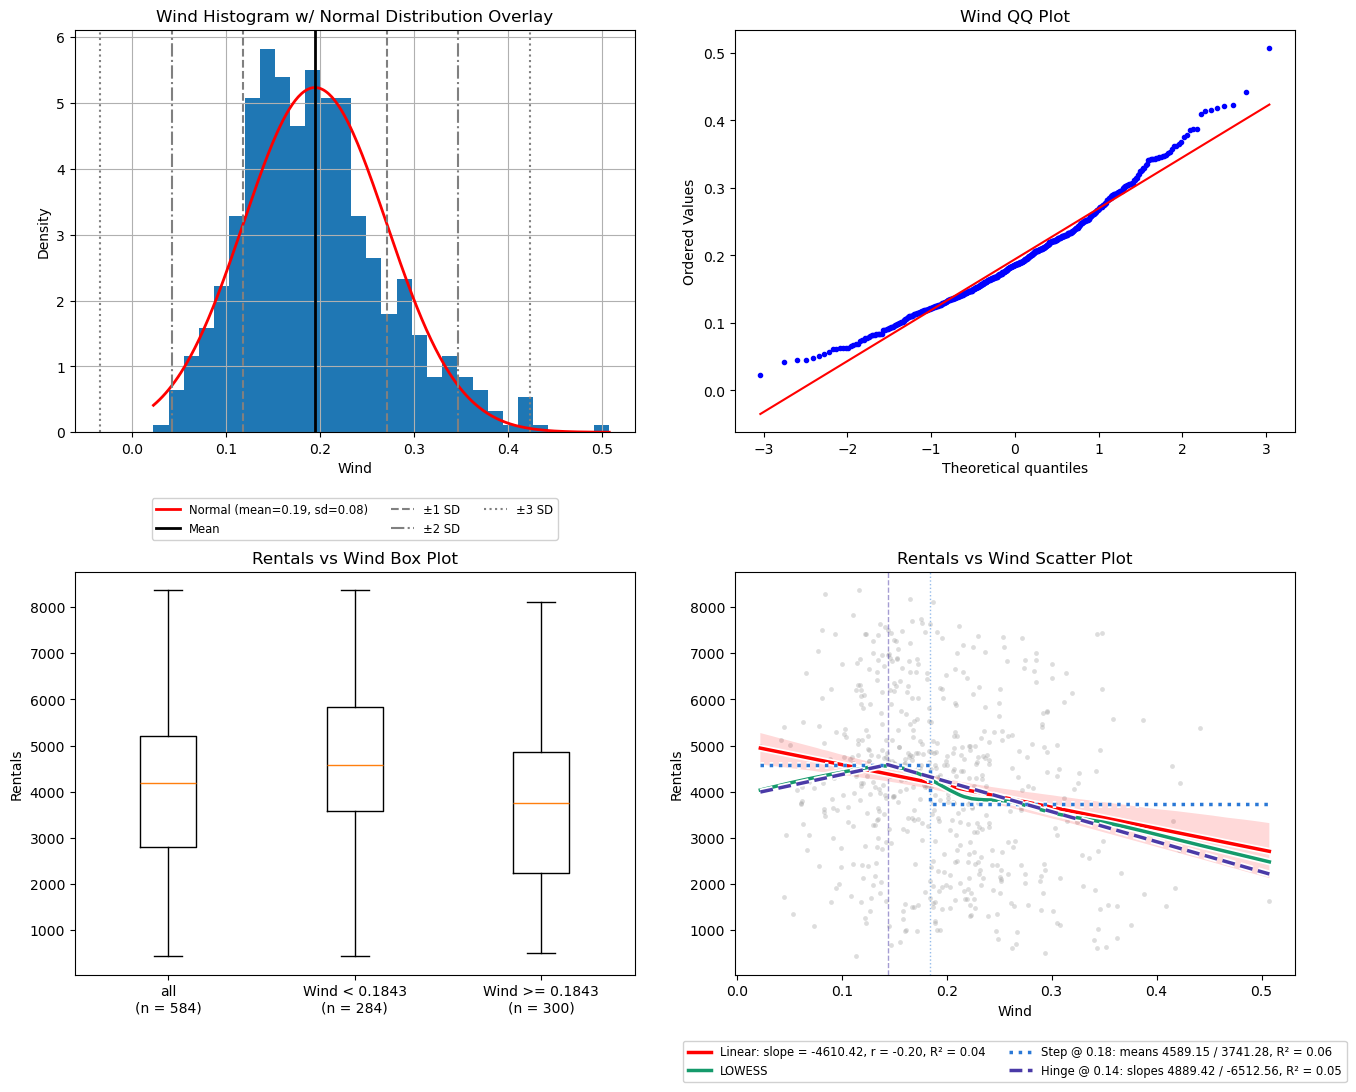

In [53]:
PLOTTING.single_feature_plots(df=wind_df, feature=wind_col, target=TARGET, threshold="auto");

#### Intervention A vs Target

In [54]:
wind_results["A"] = PIPELINES.evaluate_pipeline(
	Pipeline([("model", LinearRegression())]),
	X=wind_X, y=wind_y, folds=wind_folds,
)
display(SCORING.results_df({k: wind_results[k] for k in ["A"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
A,1757.714,102.545,1416.683,108.043,0.023,0.03,0.0,NaN,NaN,NaN,baseline,20


### Intervention B | Pull in the high tail (log)

**What it targets**
The right skew Q2B flagged: most rows sit between about 0.1 and 0.25, with a long tail up to 0.507.

**What the intervention does**
Replaces the raw value with its log (all values are positive, min 0.022):

`z = log(x)`

| x | log(x) |
|---|---|
| 0.05 | -2.996 |
| 0.10 | -2.303 |
| 0.20 | -1.609 |
| 0.40 | -0.916 |
| 0.50 | -0.693 |

The log spreads out the low values and squeezes the high ones: the gap from 0.05 to 0.10 becomes 0.693, while the gap from 0.40 to 0.50 becomes 0.223. The model becomes `Rentals = a + b·log(x)`, a curve in x that is steep at the low end and flat at the top.

**What it gives up**
It assumes the relationship has the specific log shape, with no parameter to adjust it. It also stretches the low end of the range, where few rows sit.

**Hypothesis**
If Rentals respond to relative changes in Wind more than to absolute ones, B beats A by more than the noise threshold. If the decline is already close to a straight line, B ties with A or loses to it.

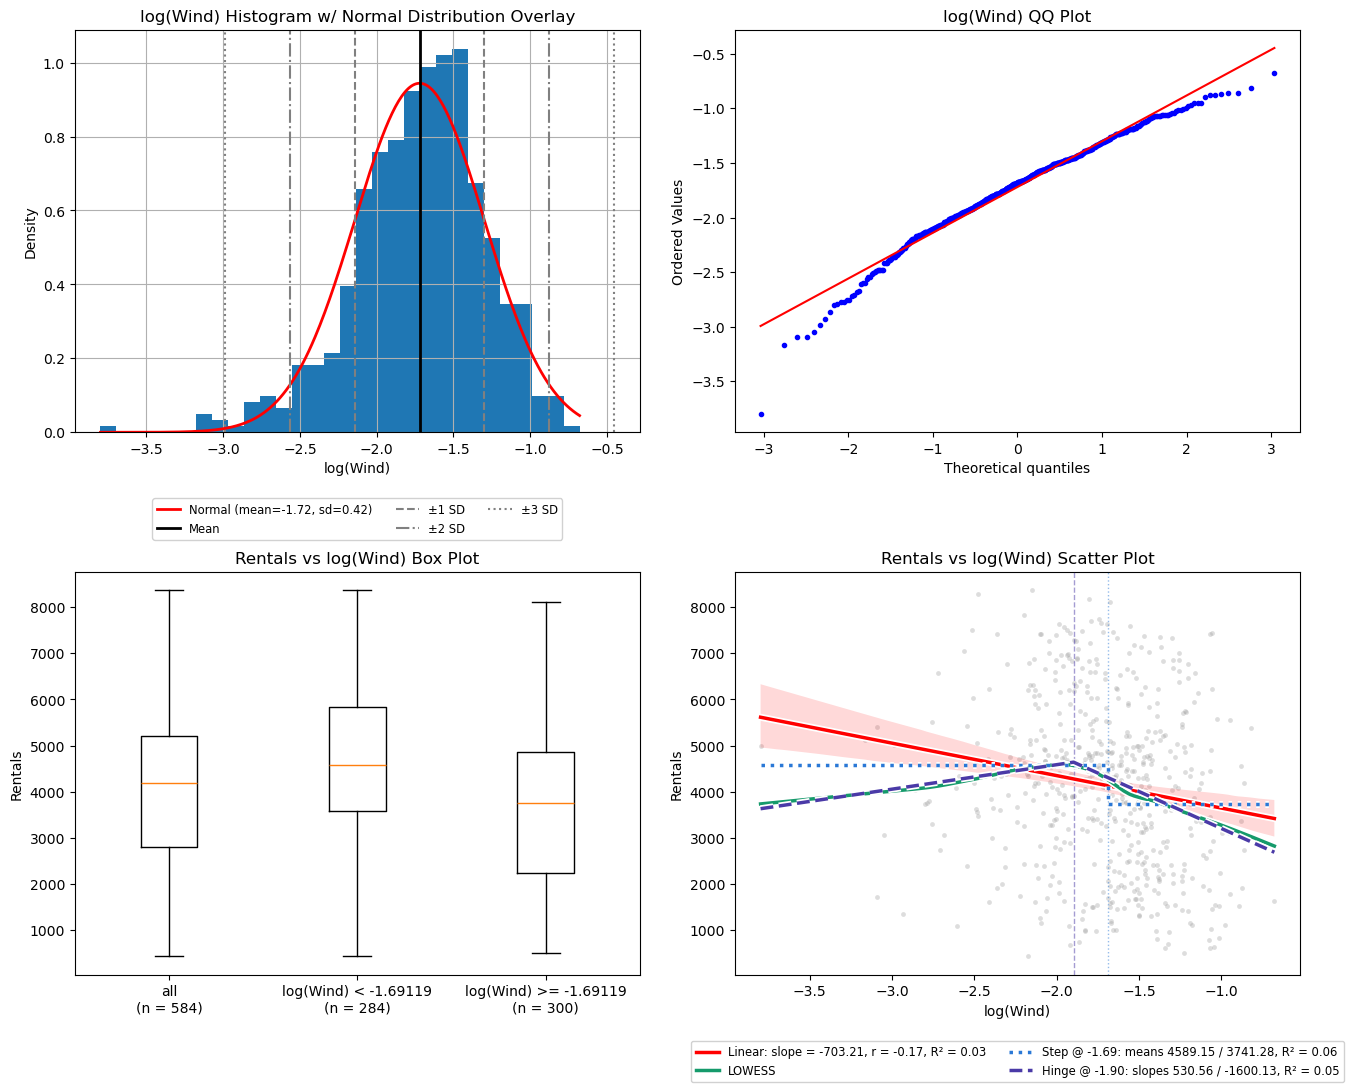

In [55]:
# fit on all wind_df rows, for illustration only (the scores below refit inside each training fold)
wind_b_df = pd.DataFrame(
	{"log(Wind)": np.ravel(FunctionTransformer(np.log).fit_transform(wind_X)), TARGET: wind_y},
	index=wind_df.index,
)
PLOTTING.single_feature_plots(df=wind_b_df, feature="log(Wind)", target=TARGET, threshold="auto");

#### Intervention B vs Target

In [56]:
wind_results["B"] = PIPELINES.evaluate_pipeline(
	Pipeline([("features", FunctionTransformer(np.log)), ("model", LinearRegression())]),
	X=wind_X, y=wind_y, folds=wind_folds,
)
display(SCORING.results_df({k: wind_results[k] for k in ["A", "B"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
A,1757.714,102.545,1416.683,108.043,0.023,0.030,0.000,NaN,NaN,NaN,baseline,20
B,1767.863,103.303,1430.950,107.684,0.012,0.027,10.148,4.758,2.133,0.977,worse,20


### Intervention C | Skew fix (Yeo-Johnson)

**What it targets**
The same right skew as B, with a transform whose strength is fit to the data.

**What the intervention does**
Replaces the raw value with its Yeo-Johnson transform, with the power parameter fit on each training fold. Yeo-Johnson reshapes the column toward a symmetric histogram, so for a right skewed column it compresses the high tail. The model becomes `Rentals = a + b·YJ(x)`.

**What it gives up**
The transform is chosen to make the histogram symmetric, not to make the relationship with Rentals linear. Those are two different goals, and only the second one helps the LR.

**Hypothesis**
Tests Q2B's "if the skew needs fixing". If the skew is what holds the raw line back, C beats A. The skew is only moderate (0.668), so C is expected to be within noise of A.

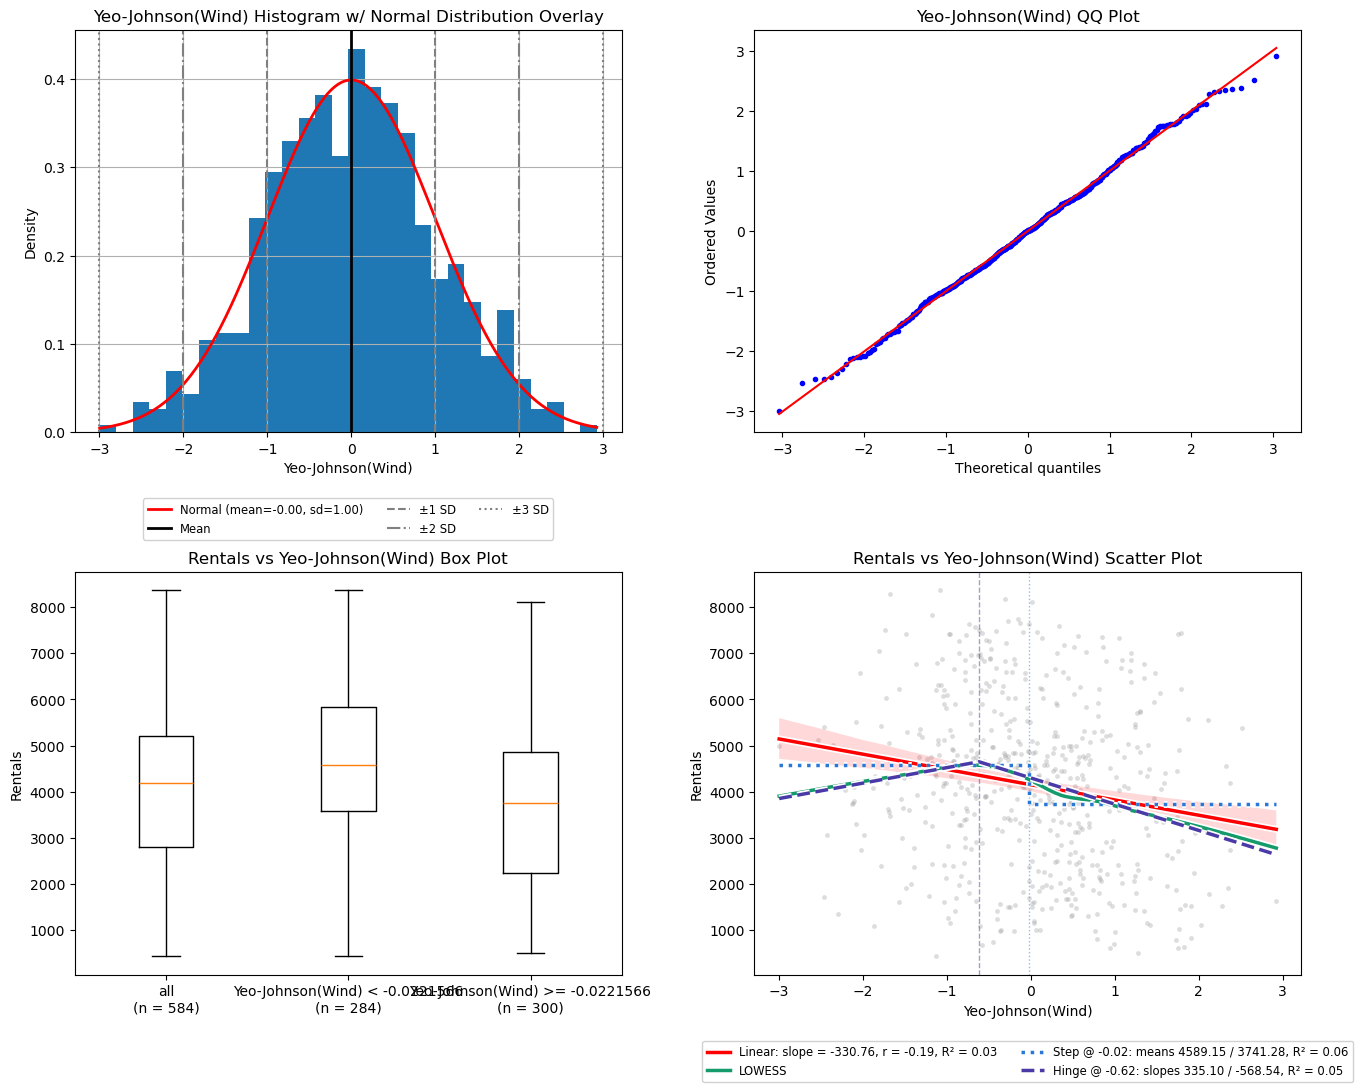

In [57]:
# fit on all wind_df rows, for illustration only (the scores below refit inside each training fold)
wind_c_df = pd.DataFrame(
	{"Yeo-Johnson(Wind)": np.ravel(PowerTransformer(method="yeo-johnson").fit_transform(wind_X)), TARGET: wind_y},
	index=wind_df.index,
)
PLOTTING.single_feature_plots(df=wind_c_df, feature="Yeo-Johnson(Wind)", target=TARGET, threshold="auto");

#### Intervention C vs Target

In [58]:
wind_results["C"] = PIPELINES.evaluate_pipeline(
	Pipeline([("features", PowerTransformer(method="yeo-johnson")), ("model", LinearRegression())]),
	X=wind_X, y=wind_y, folds=wind_folds,
)
display(SCORING.results_df({k: wind_results[k] for k in ["A", "C"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
A,1757.714,102.545,1416.683,108.043,0.023,0.030,0.000,NaN,NaN,NaN,baseline,20
C,1761.808,102.095,1422.966,107.290,0.019,0.029,4.094,2.395,1.71,0.948,worse,20


### Intervention D | Winsorize control (IQR fence clip)

**What it targets**
Control. The 12 high outliers Q2B flagged, the values above the upper IQR fence.

**What the intervention does**
Clips the raw value to the fences Q1 - 1.5·IQR and Q3 + 1.5·IQR, learned on each training fold. Every value above the upper fence becomes the upper fence value, and every value between the fences is unchanged. The model becomes `Rentals = a + b·clip(x)`.

**What it gives up**
The detail in the high tail: every high outlier gets the same feature value and so the same prediction.

**Hypothesis**
Tests Q2B's note to keep the high outliers. Expected to tie with or lose to A.

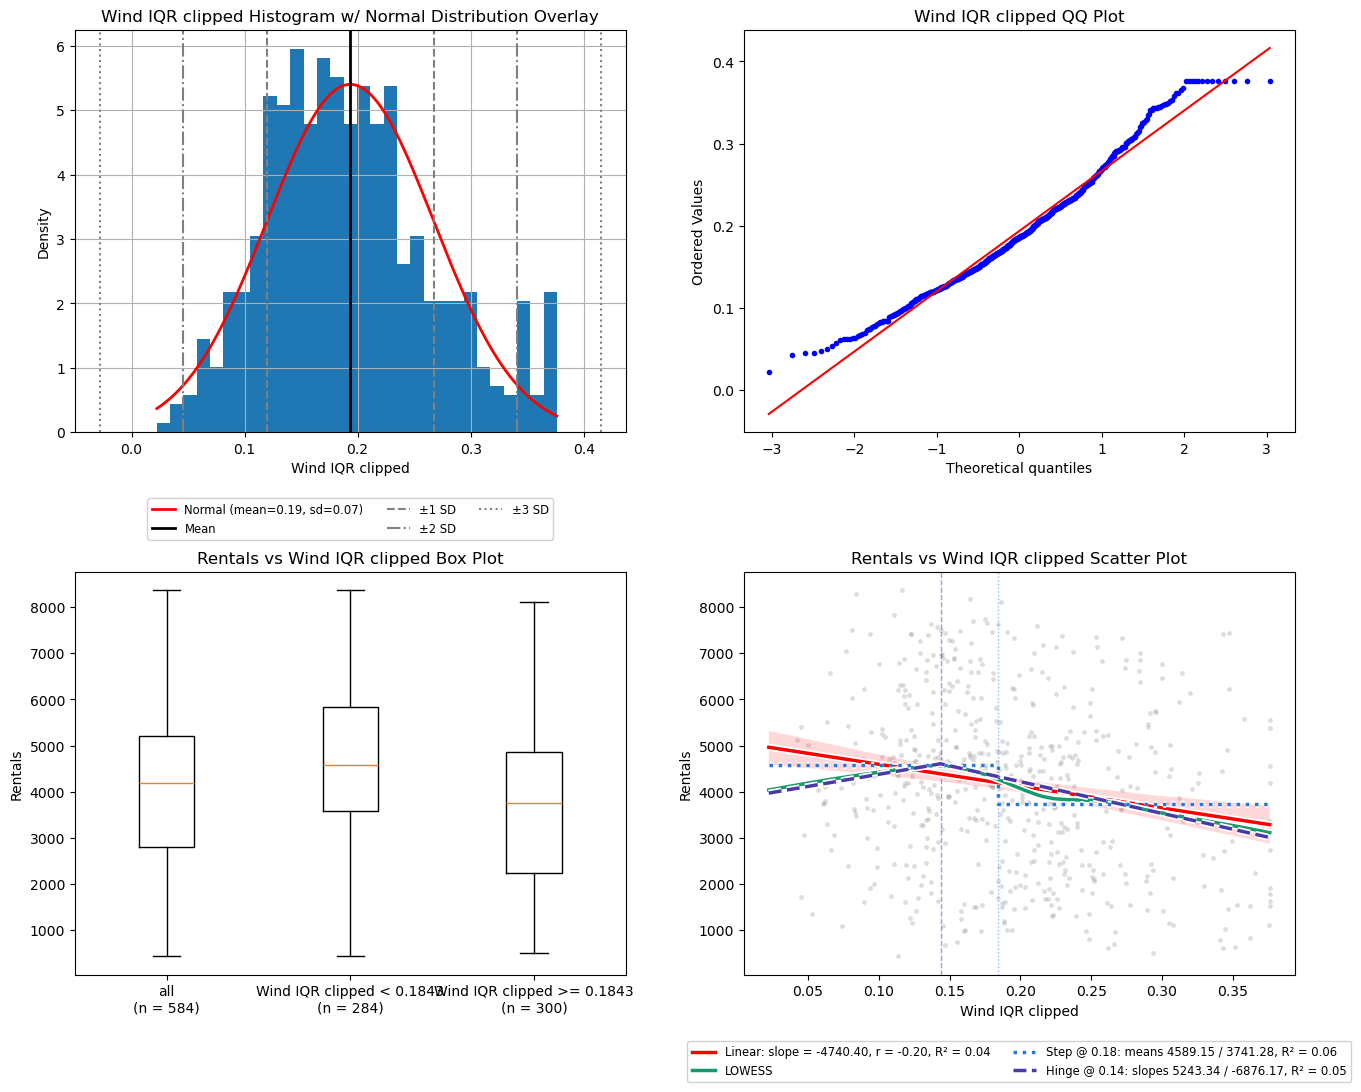

In [59]:
# fit on all wind_df rows, for illustration only (the scores below refit inside each training fold)
wind_d_df = pd.DataFrame(
	{"Wind IQR clipped": np.ravel(FEATURES.IQRClip().fit_transform(wind_X)), TARGET: wind_y},
	index=wind_df.index,
)
PLOTTING.single_feature_plots(df=wind_d_df, feature="Wind IQR clipped", target=TARGET, threshold="auto");

#### Intervention D vs Target

In [60]:
wind_results["D"] = PIPELINES.evaluate_pipeline(
	Pipeline([("features", FEATURES.IQRClip()), ("model", LinearRegression())]),
	X=wind_X, y=wind_y, folds=wind_folds,
)
display(SCORING.results_df({k: wind_results[k] for k in ["A", "D"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
A,1757.714,102.545,1416.683,108.043,0.023,0.03,0.000,NaN,NaN,NaN,baseline,20
D,1758.007,102.549,1417.216,108.398,0.023,0.03,0.293,1.043,0.281,0.609,within noise,20


### Intervention E | Low-value indicator

**What it targets**
Q2B's step fit at 0.18 scored slightly above the straight line (R² 0.06 vs 0.04), and its box plot showed a level difference between the two sides. E tests whether that split alone carries the signal.

**What the intervention does**
Replaces the raw value with one binary feature:

`i = 1 if x < t else 0`

| x | i (t = 0.18) |
|---|---|
| 0.05 | 1 |
| 0.15 | 1 |
| 0.18 | 0 |
| 0.40 | 0 |

The model becomes `Rentals = a + b·i`, which predicts one mean per side: `a` for the rows at or above t and `a + b` for the rows below it. No plot cell, since the feature is binary.

**What it gives up**
All variation within each side is erased: a row at 0.20 gets the same prediction as a row at 0.50.

**Variants**
- **E fixed (t = 0.18):** Q2B's step threshold. Q2B found it by searching all the train rows, including the rows each fold later validates on, so this variant can look optimistic.
- **E nested:** t is searched from 0.03 to 0.50 (step 0.01, since Wind only spans 0.022 to 0.507) inside each training fold (inner 4-fold CV, at least 5% of the rows on each side of t), so the validation rows never influence it. This is the honest estimate, and the thresholds it picks show where the data place it.

**Hypothesis**
If most of the signal is just "calm or windy", E matches or beats A. If Rentals keep falling as Wind rises, E loses to A.

#### Intervention E vs Target

In [61]:
wind_e_pipeline = Pipeline([("features", FEATURES.Indicator(t=0.18)), ("model", LinearRegression())])

wind_results["E fixed (t=0.18)"] = PIPELINES.evaluate_pipeline(
	wind_e_pipeline,
	X=wind_X, y=wind_y, folds=wind_folds,
)
wind_results["E nested"] = PIPELINES.evaluate_pipeline(
	FEATURES.nested_threshold(wind_e_pipeline, param="features__t", grid=wind_grid),
	X=wind_X, y=wind_y, folds=wind_folds, return_estimator=True,
)
display(SCORING.results_df({k: wind_results[k] for k in ["A", "E fixed (t=0.18)", "E nested"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
E fixed (t=0.18),1750.998,94.364,1415.230,94.960,0.030,0.031,-6.717,11.678,-0.575,0.286,within noise,20
A,1757.714,102.545,1416.683,108.043,0.023,0.030,0.000,NaN,NaN,NaN,baseline,20
E nested,1759.677,104.755,1421.026,104.289,0.021,0.033,1.963,10.795,0.182,0.571,within noise,20


In [62]:
# threshold picked by the inner search in each of the 20 folds
wind_e_picked = FEATURES.picked_thresholds(wind_results["E nested"]["estimator"], param="features__t")
display(pd.Series(wind_e_picked).value_counts().sort_index().rename_axis("E nested picked t").to_frame("folds"))

,folds
E nested picked t,
0.18,14
0.19,2
0.20,1
0.21,1
0.22,2


### Intervention F | Flexible spline ceiling

**What it targets**
Not one specific shape. A ceiling: how much of Rentals any smooth single-column shape of Wind can explain. B to E each force one shape. F tells whether those shapes leave signal behind.

**What the intervention does**
Replaces the raw value with a cubic spline basis (`SplineTransformer`, degree 3). The range of x is cut into equal-width pieces at `n_knots` knots, and the LR fits a separate cubic curve on each piece, joined smoothly at the knots. With enough knots it can follow a bend, a flat region and a steep region at the same time, wherever the data put them.

The number of knots is searched from [3, 4, 5, 6, 8, 10] inside each training fold (inner 4-fold CV), the same way the nested thresholds are (without the 5% guard, which only applies to thresholds), so the validation rows never influence it. Values outside the training range are extended in a straight line. No plot cell, since the feature is several columns.

**What it gives up**
Interpretability and simplicity: several coefficients instead of one or two, and no single threshold to carry forward. More knots can also fit noise, which the inner search is there to limit.

**Hypothesis**
- **If F scores about the same as the best of B to E:** the simple shapes already capture the signal, and the simpler one is carried forward.
- **If F is clearly better:** the simple shapes are missing part of the relationship.

#### Intervention F vs Target

In [63]:
wind_f_pipeline = Pipeline([("features", SplineTransformer(degree=3, extrapolation="linear")), ("model", LinearRegression())])

wind_results["F nested"] = PIPELINES.evaluate_pipeline(
	FEATURES.nested_threshold(wind_f_pipeline, param="features__n_knots", grid=[3, 4, 5, 6, 8, 10], min_group_frac=None),
	X=wind_X, y=wind_y, folds=wind_folds, return_estimator=True,
)
display(SCORING.results_df({k: wind_results[k] for k in ["A", "F nested"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
A,1757.714,102.545,1416.683,108.043,0.023,0.030,0.000,NaN,NaN,NaN,baseline,20
F nested,1806.678,177.986,1422.779,115.156,-0.032,0.119,48.964,65.432,0.748,0.768,within noise,20


In [64]:
# number of knots picked by the inner search in each of the 20 folds
wind_f_picked = FEATURES.picked_thresholds(wind_results["F nested"]["estimator"], param="features__n_knots")
display(pd.Series(wind_f_picked).astype(int).value_counts().sort_index().rename_axis("F nested picked n_knots").to_frame("folds"))

,folds
F nested picked n_knots,
3,11
4,1
5,5
6,1
8,2


### Comparison

In [65]:
display(SCORING.results_df(wind_results, baseline="A", holm=True))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,p (Holm),verdict,folds
intervention,,,,,,,,,,,,,
E fixed (t=0.18),1750.998,94.364,1415.230,94.960,0.030,0.031,-6.717,11.678,-0.575,0.286,1.0,within noise,20
A,1757.714,102.545,1416.683,108.043,0.023,0.030,0.000,NaN,NaN,NaN,NaN,baseline,20
D,1758.007,102.549,1417.216,108.398,0.023,0.030,0.293,1.043,0.281,0.609,1.0,within noise,20
E nested,1759.677,104.755,1421.026,104.289,0.021,0.033,1.963,10.795,0.182,0.571,1.0,within noise,20
C,1761.808,102.095,1422.966,107.290,0.019,0.029,4.094,2.395,1.710,0.948,1.0,worse,20
B,1767.863,103.303,1430.950,107.684,0.012,0.027,10.148,4.758,2.133,0.977,1.0,worse,20
F nested,1806.678,177.986,1422.779,115.156,-0.032,0.119,48.964,65.432,0.748,0.768,1.0,within noise,20


## Wind Results

- **Nothing beats the raw column.** No intervention is a candidate or significant, and every `p (Holm)` is 1.0. A scores rmse 1757.714 and r2 0.023.
- **The indicator is the only one with a lower rmse, and it is within noise.** E fixed (t = 0.18) scores 1750.998 (Δ -6.717, Δ / SE -0.575), and E nested is 1.963 above A, even though it picked t = 0.18 in 14 of 20 folds.
- **Fixing the skew makes it worse.** B (log, Δ +10.148) and C (Yeo-Johnson, Δ +4.094) are both labelled worse. The moderate skew Q2B flagged is not what limits this attribute.
- **Clipping the outliers changes nothing** (D, Δ +0.293, within noise), which supports Q2B's note to keep them.
- **The spline is the worst and the least stable:** F nested scores rmse 1806.678 with r2 -0.032, and its rmse sd across folds is 177.986, against 102.545 for A.

#### Carry forward

- **A (raw), with no treatment.**
- **Drop:** B, C, D, E and F.
- Wind is weak on its own (r2 0.023), so it stays in the multi-feature model only if it improves it.

## Season

**What Q2B found**
- **4 levels** with 170, 184, 141 and 89 train rows.
- **Strong relationship with Rentals:** level means R² = 0.37.
- **The means do not follow the code order:** 2,651 / 4,992 / 5,179 / 3,664 for levels 1 to 4.

**What is tested**
- **A:** the code as a number (baseline).
- **B:** one-hot encoding.

**Note on Year**
This section stays single-attribute, like the rest of the notebook. Train ends on 2012-08-06, so months 9 to 12 only have first-year rows (Q2B and the `Month` by `Year` table above), and Q2B's Year section shows the second year runs higher (mean 5,400 vs 3,406). The season effects measured here therefore mix in part of the year effect. The comparison between encodings is still fair, since every encoding sees the same rows. Separating the two (this attribute with `Year` in the model) is left to Q2D. `Season` follows `Month` (see Category Overlap above), so the same applies to it.

In [66]:
season_col = "Season"
season_df = train_df[[season_col, TARGET]]
season_X = season_df[[season_col]]
season_y = season_df[TARGET]

season_folds = PIPELINES.make_folds(season_X, seeds=SEEDS)
season_results = {}

print(f"rows used: {len(season_df)} of {len(train_df)}")
print(f"folds: {len(season_folds)}")

rows used: 584 of 584
folds: 20


### Intervention A | Baseline (code as a number)

**What it targets**
Nothing. A is the reference that every other intervention is measured against. It is also what a model does with this column if it is left exactly as it is stored.

**What the intervention does**
The LR gets the Season code `x` (1 to 4) as if it were a quantity and fits one straight line:

`Rentals = a + b·x`

The plots below are Q2B's view of the column, kept here for reference.

**What it gives up**
The line treats the codes as evenly spaced amounts: each step up in the code moves the prediction by the same b, in the same direction. Q2B's level means go up from level 1 to level 3 and back down at level 4, which a straight line cannot follow.

**Hypothesis**
A sets the bar. Every other intervention must beat A by more than the noise threshold to be worth carrying forward. Otherwise A is kept as the simpler model.

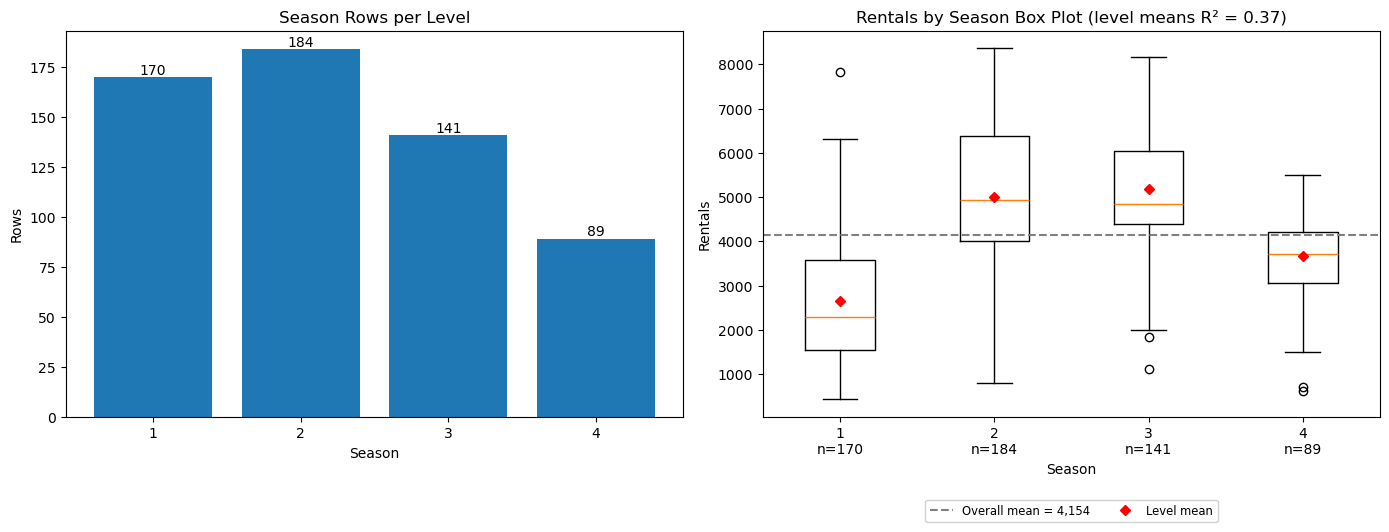

In [67]:
Q2_PLOTTING.categorical_feature_plots(df=season_df, feature=season_col, target=TARGET);

#### Intervention A vs Target

In [68]:
season_results["A"] = PIPELINES.evaluate_pipeline(
	Pipeline([("model", LinearRegression())]),
	X=season_X, y=season_y, folds=season_folds,
)
display(SCORING.results_df({k: season_results[k] for k in ["A"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
A,1714.845,94.05,1398.597,93.49,0.07,0.03,0.0,NaN,NaN,NaN,baseline,20


### Intervention B | One-hot encoding

**What it targets**
The codes are labels, not quantities. Q2B's level table shows one Rentals mean per level, and a straight line through the codes can only follow those means if they happen to fall on a line.

**What the intervention does**
Replaces the code with one 0 / 1 column per level, leaving out the first level (`OneHotEncoder(drop="first")`), so 4 levels become 3 columns:

| code | [level 2, level 3, level 4] |
|---|---|
| 1 | [0, 0, 0] |
| 2 | [1, 0, 0] |
| 3 | [0, 1, 0] |
| 4 | [0, 0, 1] |

The model becomes `Rentals = a + b₂·[level 2] + b₃·[level 3] + ...`, which predicts one mean per level: `a` for the first level and `a + bₖ` for level k. This is the model behind Q2B's level means R².

**What it gives up**
3 coefficients instead of 1, each estimated from only the rows at its level. The order of the codes is no longer used at all.

**Hypothesis**
Q2B's means are not in code order, so B is expected to beat A by a wide margin.

#### Intervention B vs Target

In [69]:
season_results["B"] = PIPELINES.evaluate_pipeline(
	Pipeline([("features", OneHotEncoder(drop="first", sparse_output=False)), ("model", LinearRegression())]),
	X=season_X, y=season_y, folds=season_folds,
)
display(SCORING.results_df({k: season_results[k] for k in ["A", "B"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
B,1435.842,61.024,1146.600,58.27,0.345,0.057,-279.003,41.861,-6.665,0.0,candidate,20
A,1714.845,94.050,1398.597,93.49,0.070,0.030,0.000,NaN,NaN,NaN,baseline,20


### Comparison

In [70]:
display(SCORING.results_df(season_results, baseline="A", holm=True))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,p (Holm),verdict,folds
intervention,,,,,,,,,,,,,
B,1435.842,61.024,1146.600,58.27,0.345,0.057,-279.003,41.861,-6.665,0.0,0.0,significant,20
A,1714.845,94.050,1398.597,93.49,0.070,0.030,0.000,NaN,NaN,NaN,NaN,baseline,20


## Season Results

- **One-hot is significant and the gain is large.** B scores rmse 1435.842 against A's 1714.845 (Δ -279.003, Δ / SE -6.665, `p (Holm)` 0.0).
- **The code as a number hides most of the signal.** A's r2 is 0.070 and B's is 0.345, close to Q2B's level means R² of 0.37, which was scored on its own training rows.

#### Carry forward

- **B (one-hot).** Never the code as a number.
- Season and Month are redundant (r = 0.862) and Month scores better on its own (see Month Results), so Season is the second choice of the two.
- The year effect is mixed into these scores (see the note on Year above).

## Month

**What Q2B found**
- **12 levels.** Months 1 to 7 have 57 to 62 train rows each, month 8 has 37, and months 9 to 12 have 30 or 31.
- **Strongest categorical relationship with Rentals:** level means R² = 0.45.
- **Rises, then falls.** The mean climbs from 2,176 at month 1 to 5,772 at month 6, then drops back to 2,817 at month 12.

**What is tested**
- **A:** the code as a number (baseline).
- **B:** one-hot encoding.
- **C:** cyclical (sine / cosine) encoding.

**Note on Year**
This section stays single-attribute, like the rest of the notebook. Train ends on 2012-08-06, so months 9 to 12 only have first-year rows (Q2B and the `Month` by `Year` table above), and Q2B's Year section shows the second year runs higher (mean 5,400 vs 3,406). The month effects measured here therefore mix in part of the year effect. The comparison between encodings is still fair, since every encoding sees the same rows. Separating the two (this attribute with `Year` in the model) is left to Q2D.

In [71]:
month_col = "Month"
month_df = train_df[[month_col, TARGET]]
month_X = month_df[[month_col]]
month_y = month_df[TARGET]

month_folds = PIPELINES.make_folds(month_X, seeds=SEEDS)
month_results = {}

print(f"rows used: {len(month_df)} of {len(train_df)}")
print(f"folds: {len(month_folds)}")

rows used: 584 of 584
folds: 20


### Intervention A | Baseline (code as a number)

**What it targets**
Nothing. A is the reference that every other intervention is measured against. It is also what a model does with this column if it is left exactly as it is stored.

**What the intervention does**
The LR gets the Month code `x` (1 to 12) as if it were a quantity and fits one straight line:

`Rentals = a + b·x`

The plots below are Q2B's view of the column, kept here for reference.

**What it gives up**
The line treats the codes as evenly spaced amounts: each step up in the code moves the prediction by the same b, in the same direction. Q2B's level means rise to month 6 and fall back by month 12, so a straight line through the codes ends up close to flat.

**Hypothesis**
A sets the bar. Every other intervention must beat A by more than the noise threshold to be worth carrying forward. Otherwise A is kept as the simpler model.

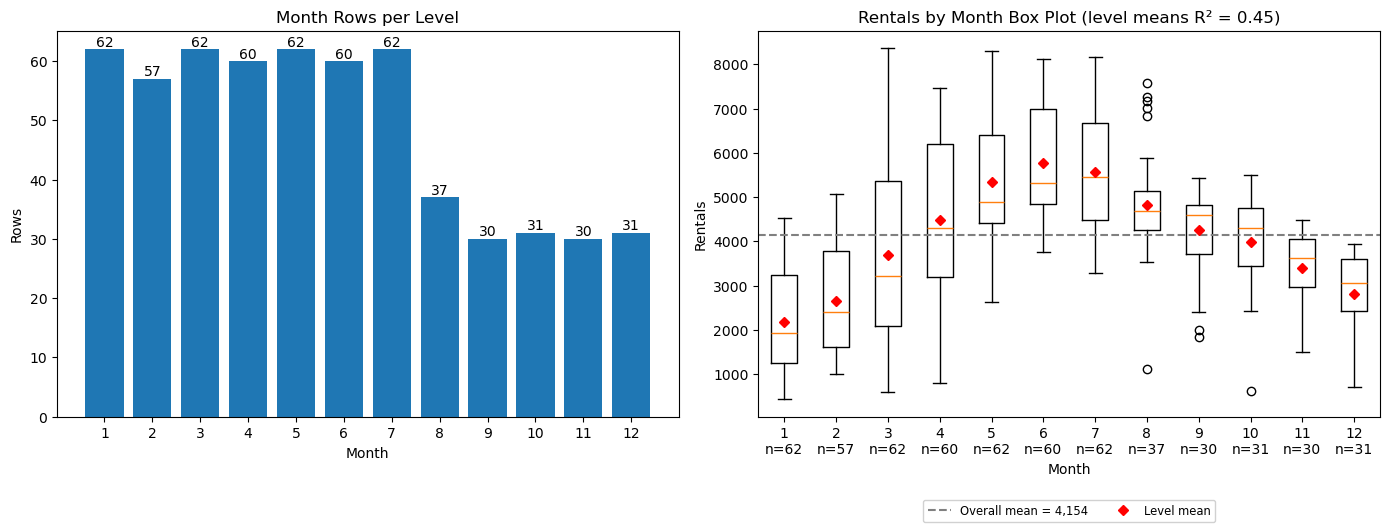

In [72]:
Q2_PLOTTING.categorical_feature_plots(df=month_df, feature=month_col, target=TARGET);

#### Intervention A vs Target

In [73]:
month_results["A"] = PIPELINES.evaluate_pipeline(
	Pipeline([("model", LinearRegression())]),
	X=month_X, y=month_y, folds=month_folds,
)
display(SCORING.results_df({k: month_results[k] for k in ["A"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
A,1753.064,103.002,1427.262,103.489,0.028,0.027,0.0,NaN,NaN,NaN,baseline,20


### Intervention B | One-hot encoding

**What it targets**
The codes are labels, not quantities. Q2B's level table shows one Rentals mean per level, and a straight line through the codes can only follow those means if they happen to fall on a line.

**What the intervention does**
Replaces the code with one 0 / 1 column per level, leaving out the first level (`OneHotEncoder(drop="first")`), so 12 levels become 11 columns:

| code | [month 2, month 3, ..., month 12] |
|---|---|
| 1 | [0, 0, ..., 0] |
| 2 | [1, 0, ..., 0] |
| 12 | [0, 0, ..., 1] |

The model becomes `Rentals = a + b₂·[level 2] + b₃·[level 3] + ...`, which predicts one mean per level: `a` for the first level and `a + bₖ` for level k. This is the model behind Q2B's level means R².

**What it gives up**
11 coefficients instead of 1, each estimated from only the rows at its level. The order of the codes is no longer used at all.

**Hypothesis**
Q2B's means rise and then fall, so B is expected to beat A by a wide margin. The open question is the cost of 11 coefficients, some resting on 30 rows.

#### Intervention B vs Target

In [74]:
month_results["B"] = PIPELINES.evaluate_pipeline(
	Pipeline([("features", OneHotEncoder(drop="first", sparse_output=False)), ("model", LinearRegression())]),
	X=month_X, y=month_y, folds=month_folds,
)
display(SCORING.results_df({k: month_results[k] for k in ["A", "B"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
B,1347.629,76.547,1123.871,61.205,0.424,0.055,-405.435,39.846,-10.175,0.0,candidate,20
A,1753.064,103.002,1427.262,103.489,0.028,0.027,0.000,NaN,NaN,NaN,baseline,20


### Intervention C | Cyclical encoding (sine / cosine)

**What it targets**
The same rise and fall as B, with 2 columns instead of 11. It also fixes something neither A nor B knows: month 12 is next to month 1.

**What the intervention does**
Places each month on a circle and replaces the code `m` with its two coordinates:

`[sin(2π·m / 12), cos(2π·m / 12)]`

| m | features [sin, cos] |
|---|---|
| 1 | [0.500, 0.866] |
| 3 | [1.000, 0.000] |
| 6 | [0.000, -1.000] |
| 9 | [-1.000, 0.000] |
| 12 | [0.000, 1.000] |

The model becomes `Rentals = a + b·sin + c·cos`, one smooth wave over the year. The LR picks where the wave peaks and how tall it is. No plot cell, since the feature is two columns.

**What it gives up**
The shape is fixed to a single symmetric wave: one peak and one trough exactly six months apart, with the rise and the fall mirror images of each other. Any month that departs from the wave cannot be fitted.

**Hypothesis**
If the monthly pattern is close to one smooth wave, C scores close to B with 2 coefficients instead of 11. If the months depart from a wave (ex a sharper rise than fall), C loses to B but still beats A.

#### Intervention C vs Target

In [75]:
month_results["C"] = PIPELINES.evaluate_pipeline(
	Pipeline([("features", Q2_FEATURES.Cyclical(period=12)), ("model", LinearRegression())]),
	X=month_X, y=month_y, folds=month_folds,
)
display(SCORING.results_df({k: month_results[k] for k in ["A", "C"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
C,1348.604,67.190,1136.661,53.253,0.423,0.047,-404.46,37.351,-10.829,0.0,candidate,20
A,1753.064,103.002,1427.262,103.489,0.028,0.027,0.00,NaN,NaN,NaN,baseline,20


### Comparison

In [76]:
display(SCORING.results_df(month_results, baseline="A", holm=True))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,p (Holm),verdict,folds
intervention,,,,,,,,,,,,,
B,1347.629,76.547,1123.871,61.205,0.424,0.055,-405.435,39.846,-10.175,0.0,0.0,significant,20
C,1348.604,67.190,1136.661,53.253,0.423,0.047,-404.460,37.351,-10.829,0.0,0.0,significant,20
A,1753.064,103.002,1427.262,103.489,0.028,0.027,0.000,NaN,NaN,NaN,NaN,baseline,20


## Month Results

- **Both encodings are significant and the gain is the largest in the notebook.** A scores rmse 1753.064 (r2 0.028). B (one-hot) scores 1347.629 (Δ -405.435, r2 0.424) and C (sine / cosine) scores 1348.604 (Δ -404.460, r2 0.423), both with `p (Holm)` 0.0.
- **The cyclical encoding ties one-hot with 2 coefficients instead of 11.** The two are 1 rmse apart, and C varies less across folds (rmse sd 67.190 vs 76.547). The monthly pattern is close to one smooth wave.
- **The code as a number is nearly useless** (r2 0.028), although Pearson r with Rentals is 0.20. A straight line through the codes cannot follow means that rise and then fall.
- **Month is the strongest single categorical attribute:** its best rmse (1347.629) is below Season's (1435.842) and Year's (1508.723).

#### Carry forward

- **C (sine / cosine)** as the main candidate, since it matches one-hot with far fewer coefficients.
- **B (one-hot)** as the alternative.
- **Month ahead of Season,** since the two are redundant and Month scores better.
- The year effect is mixed into these scores (months 9 to 12 only have first year rows), so Month must be scored again with `Year` in the model in Q2D.

## Weather

**What Q2B found**
- **3 levels with very uneven row counts:** 377, 189 and only 18 train rows.
- **Weak relationship with Rentals:** level means R² = 0.10.
- **Rentals fall as the code rises, in unequal steps:** means of 4,510 / 3,665 / 1,820. The drop from level 2 to level 3 is larger than the drop from level 1 to level 2.

**What is tested**
- **A:** the code as a number (baseline).
- **B:** one-hot encoding.
- **C:** one-hot encoding with level 3 merged into level 2.

In [77]:
weather_col = "Weather"
weather_df = train_df[[weather_col, TARGET]]
weather_X = weather_df[[weather_col]]
weather_y = weather_df[TARGET]

weather_folds = PIPELINES.make_folds(weather_X, seeds=SEEDS)
weather_results = {}

print(f"rows used: {len(weather_df)} of {len(train_df)}")
print(f"folds: {len(weather_folds)}")

rows used: 584 of 584
folds: 20


### Intervention A | Baseline (code as a number)

**What it targets**
Nothing. A is the reference that every other intervention is measured against. It is also what a model does with this column if it is left exactly as it is stored.

**What the intervention does**
The LR gets the Weather code `x` (1 to 3) as if it were a quantity and fits one straight line:

`Rentals = a + b·x`

The plots below are Q2B's view of the column, kept here for reference.

**What it gives up**
The line treats the codes as evenly spaced amounts: each step up in the code moves the prediction by the same b, in the same direction. Q2B's means do fall in code order, so a line can follow the direction, but it has to use the same step from level 1 to 2 as from level 2 to 3.

**Hypothesis**
A sets the bar. Every other intervention must beat A by more than the noise threshold to be worth carrying forward. Otherwise A is kept as the simpler model.

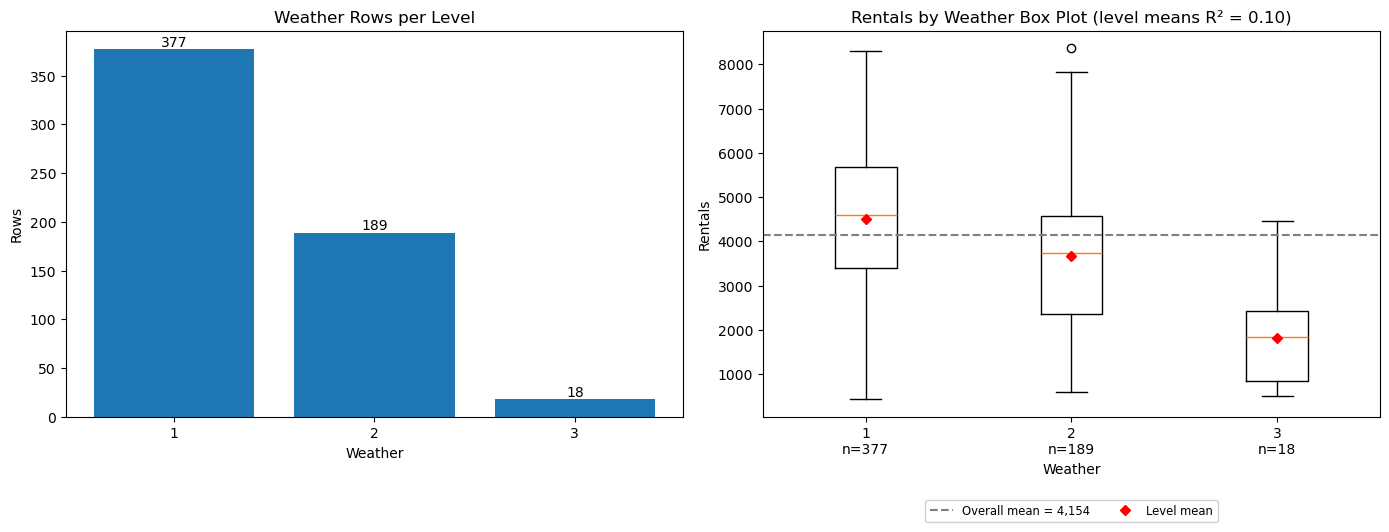

In [78]:
Q2_PLOTTING.categorical_feature_plots(df=weather_df, feature=weather_col, target=TARGET);

#### Intervention A vs Target

In [79]:
weather_results["A"] = PIPELINES.evaluate_pipeline(
	Pipeline([("model", LinearRegression())]),
	X=weather_X, y=weather_y, folds=weather_folds,
)
display(SCORING.results_df({k: weather_results[k] for k in ["A"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
A,1705.563,95.314,1360.241,89.131,0.079,0.051,0.0,NaN,NaN,NaN,baseline,20


### Intervention B | One-hot encoding

**What it targets**
The codes are labels, not quantities. Q2B's level table shows one Rentals mean per level, and a straight line through the codes can only follow those means if they happen to fall on a line.

**What the intervention does**
Replaces the code with one 0 / 1 column per level, leaving out the first level (`OneHotEncoder(drop="first")`), so 3 levels become 2 columns:

| code | [level 2, level 3] |
|---|---|
| 1 | [0, 0] |
| 2 | [1, 0] |
| 3 | [0, 1] |

The model becomes `Rentals = a + b₂·[level 2] + b₃·[level 3] + ...`, which predicts one mean per level: `a` for the first level and `a + bₖ` for level k. This is the model behind Q2B's level means R².

**What it gives up**
2 coefficients instead of 1, each estimated from only the rows at its level. The order of the codes is no longer used at all.

**Hypothesis**
The steps between levels are unequal, so B should fit the level means better than A. The gain may be small: the means are in code order, and the level that departs most from the line (level 3) has only 18 rows.

#### Intervention B vs Target

In [80]:
weather_results["B"] = PIPELINES.evaluate_pipeline(
	Pipeline([("features", OneHotEncoder(drop="first", sparse_output=False)), ("model", LinearRegression())]),
	X=weather_X, y=weather_y, folds=weather_folds,
)
display(SCORING.results_df({k: weather_results[k] for k in ["A", "B"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
B,1700.256,96.242,1353.170,90.388,0.085,0.048,-5.307,5.269,-1.007,0.163,candidate,20
A,1705.563,95.314,1360.241,89.131,0.079,0.051,0.000,NaN,NaN,NaN,baseline,20


### Intervention C | One-hot with level 3 merged into level 2

**What it targets**
The rare level. Level 3 has 18 train rows, so each training fold estimates its coefficient from about 13 or 14 rows.

**What the intervention does**
Replaces every code 3 with code 2 (`MergeLevels({3: 2})`), then one-hot encodes the two levels that remain, which leaves a single 0 / 1 column:

| code | merged code | [level 2 or 3] |
|---|---|---|
| 1 | 1 | [0] |
| 2 | 2 | [1] |
| 3 | 2 | [1] |

The model becomes `Rentals = a + b·[level 2 or 3]`, one mean for level 1 and one mean for everything else.

**What it gives up**
The level with the largest gap from the overall mean (-2333.210 in Q2B) is no longer told apart from level 2.

**Hypothesis**
If 18 rows are too few to estimate level 3 reliably, C ties with B using one column fewer. If the level 3 effect is real and stable across folds, C loses to B.

#### Intervention C vs Target

In [81]:
weather_results["C"] = PIPELINES.evaluate_pipeline(
	Pipeline([("merge", Q2_FEATURES.MergeLevels({3: 2})), ("features", OneHotEncoder(drop="first", sparse_output=False)), ("model", LinearRegression())]),
	X=weather_X, y=weather_y, folds=weather_folds,
)
display(SCORING.results_df({k: weather_results[k] for k in ["A", "C"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
A,1705.563,95.314,1360.241,89.131,0.079,0.051,0.000,NaN,NaN,NaN,baseline,20
C,1728.154,96.334,1387.144,91.451,0.055,0.046,22.591,6.868,3.289,0.998,worse,20


### Comparison

In [82]:
display(SCORING.results_df(weather_results, baseline="A", holm=True))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,p (Holm),verdict,folds
intervention,,,,,,,,,,,,,
B,1700.256,96.242,1353.170,90.388,0.085,0.048,-5.307,5.269,-1.007,0.163,0.327,candidate,20
A,1705.563,95.314,1360.241,89.131,0.079,0.051,0.000,NaN,NaN,NaN,NaN,baseline,20
C,1728.154,96.334,1387.144,91.451,0.055,0.046,22.591,6.868,3.289,0.998,0.998,worse,20


## Weather Results

- **One-hot is a candidate, not significant.** B scores rmse 1700.256 against A's 1705.563 (Δ -5.307, Δ / SE -1.007, `p (Holm)` 0.327). The gain is small because the level means are already in code order, so the straight line follows most of the pattern (A's r2 is 0.079, B's is 0.085).
- **Merging the rare level makes it worse.** C scores rmse 1728.154 (Δ +22.591, Δ / SE 3.289, verdict worse). Level 3 has only 18 rows, but its effect is stable enough across folds that hiding it costs more than estimating it.
- Weather stays a weak attribute either way: its best r2 is 0.085.

#### Carry forward

- **B (one-hot)** as the candidate, with level 3 kept as its own level.
- **A (code as a number)** as the simpler alternative, since B's gain is only about 1 SE.
- **Drop:** C.

## Weekday

**What Q2B found**
- **7 evenly filled levels:** 83 or 84 train rows each.
- **No relationship with Rentals:** level means R² = 0.00. The means run from 3,997 to 4,290.
- Q2B listed it as a candidate to drop.

**What is tested**
- **A:** the code as a number (baseline).
- **B:** one-hot encoding.

In [83]:
weekday_col = "Weekday"
weekday_df = train_df[[weekday_col, TARGET]]
weekday_X = weekday_df[[weekday_col]]
weekday_y = weekday_df[TARGET]

weekday_folds = PIPELINES.make_folds(weekday_X, seeds=SEEDS)
weekday_results = {}

print(f"rows used: {len(weekday_df)} of {len(train_df)}")
print(f"folds: {len(weekday_folds)}")

rows used: 584 of 584
folds: 20


### Intervention A | Baseline (code as a number)

**What it targets**
Nothing. A is the reference that every other intervention is measured against. It is also what a model does with this column if it is left exactly as it is stored.

**What the intervention does**
The LR gets the Weekday code `x` (0 to 6) as if it were a quantity and fits one straight line:

`Rentals = a + b·x`

The plots below are Q2B's view of the column, kept here for reference.

**What it gives up**
The line treats the codes as evenly spaced amounts: each step up in the code moves the prediction by the same b, in the same direction. Q2B found almost no difference between the levels, so there is little for either a line or an encoding to follow.

**Hypothesis**
A sets the bar. Every other intervention must beat A by more than the noise threshold to be worth carrying forward. Otherwise A is kept as the simpler model.

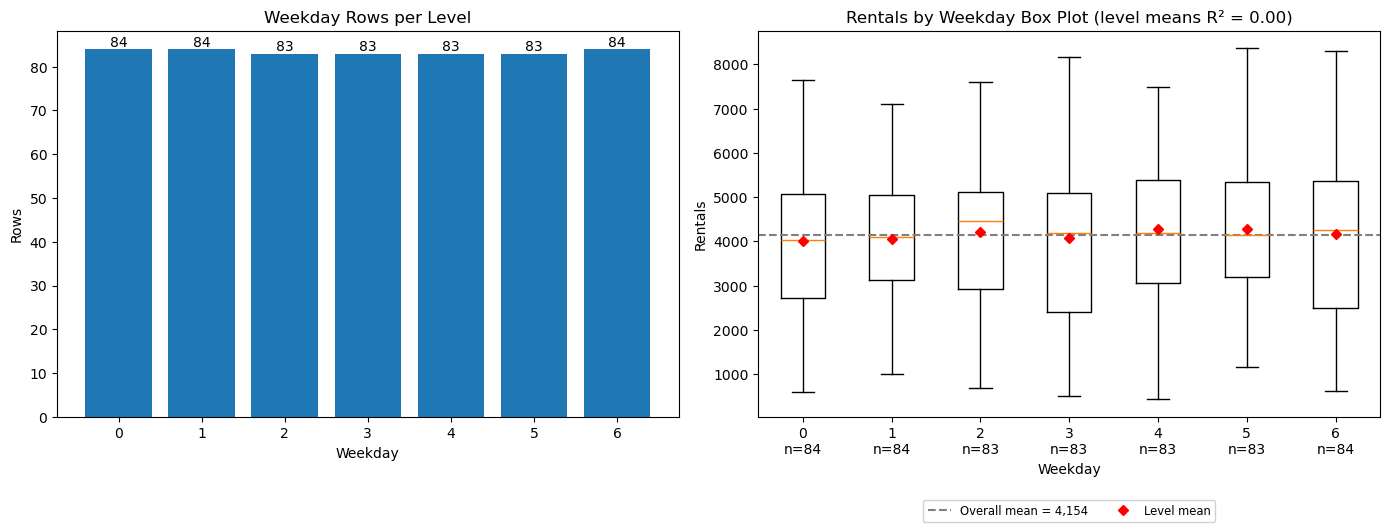

In [84]:
Q2_PLOTTING.categorical_feature_plots(df=weekday_df, feature=weekday_col, target=TARGET);

#### Intervention A vs Target

In [85]:
weekday_results["A"] = PIPELINES.evaluate_pipeline(
	Pipeline([("model", LinearRegression())]),
	X=weekday_X, y=weekday_y, folds=weekday_folds,
)
display(SCORING.results_df({k: weekday_results[k] for k in ["A"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
A,1792.124,106.998,1451.18,110.813,-0.015,0.025,0.0,NaN,NaN,NaN,baseline,20


### Intervention B | One-hot encoding

**What it targets**
The codes are labels, not quantities. Q2B's level table shows one Rentals mean per level, and a straight line through the codes can only follow those means if they happen to fall on a line.

**What the intervention does**
Replaces the code with one 0 / 1 column per level, leaving out the first level (`OneHotEncoder(drop="first")`), so 7 levels become 6 columns:

| code | [day 1, day 2, ..., day 6] |
|---|---|
| 0 | [0, 0, ..., 0] |
| 1 | [1, 0, ..., 0] |
| 6 | [0, 0, ..., 1] |

The model becomes `Rentals = a + b₂·[level 2] + b₃·[level 3] + ...`, which predicts one mean per level: `a` for the first level and `a + bₖ` for level k. This is the model behind Q2B's level means R².

**What it gives up**
6 coefficients instead of 1, each estimated from only the rows at its level. The order of the codes is no longer used at all.

**Hypothesis**
Q2B found no difference between the levels, so B is expected to be within noise of A, or worse because of its 6 coefficients. Either result supports dropping the attribute.

#### Intervention B vs Target

In [86]:
weekday_results["B"] = PIPELINES.evaluate_pipeline(
	Pipeline([("features", OneHotEncoder(drop="first", sparse_output=False)), ("model", LinearRegression())]),
	X=weekday_X, y=weekday_y, folds=weekday_folds,
)
display(SCORING.results_df({k: weekday_results[k] for k in ["A", "B"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
A,1792.124,106.998,1451.180,110.813,-0.015,0.025,0.000,NaN,NaN,NaN,baseline,20
B,1807.898,105.940,1464.765,111.053,-0.033,0.029,15.774,7.111,2.218,0.981,worse,20


### Comparison

In [87]:
display(SCORING.results_df(weekday_results, baseline="A", holm=True))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,p (Holm),verdict,folds
intervention,,,,,,,,,,,,,
A,1792.124,106.998,1451.180,110.813,-0.015,0.025,0.000,NaN,NaN,NaN,NaN,baseline,20
B,1807.898,105.940,1464.765,111.053,-0.033,0.029,15.774,7.111,2.218,0.981,0.981,worse,20


## Weekday Results

- **Neither version explains anything.** A scores rmse 1792.124 with r2 -0.015, and B (one-hot) scores 1807.898 with r2 -0.033. Both are behind the mean-only model in the next section (rmse 1788.425 on the same folds).
- **One-hot is worse than the code** (Δ +15.774, Δ / SE 2.218, verdict worse): 6 coefficients with nothing to fit only add noise.
- This matches Q2B, where the level means ran from 3,997 to 4,290 with an R² of 0.00.

#### Carry forward

- **Drop Weekday** as a single attribute. It has no relationship with total Rentals in either encoding.
- IsWorkday is determined by Weekday and IsHoliday (see Category Overlap), and it shows no relationship either (next section).

## Year, IsHoliday and IsWorkday

**What Q2B found**
- **Year:** 365 and 219 train rows. Clear shift between the levels (level means R² = 0.29, means of 3,406 vs 5,400).
- **IsHoliday:** 568 and 16 train rows. No measurable relationship (R² = 0.00).
- **IsWorkday:** 184 and 400 train rows. No relationship (R² = 0.00).

**What is tested**
These three are already 0 / 1, so there is no encoding to change and no shape to fit: a straight line through two points is the two level means. Each attribute is scored as it is and compared with a model that ignores every attribute.

- **Mean only (baseline):** `DummyRegressor`, which predicts the mean Rentals of the training fold for every row.
- **Year, IsHoliday, IsWorkday:** `Rentals = a + b·x`, one mean per level.

**Hypothesis**
Year beats the mean by a wide margin. IsHoliday and IsWorkday are within noise of the mean, which would support Q2B's note that both are candidates to drop.

In [88]:
binary_df = train_df[BINARY + [TARGET]]
binary_y = binary_df[TARGET]

binary_folds = PIPELINES.make_folds(binary_df[BINARY], seeds=SEEDS)
binary_results = {}

print(f"rows used: {len(binary_df)} of {len(train_df)}")
print(f"folds: {len(binary_folds)}")

rows used: 584 of 584
folds: 20


### Comparison

In [89]:
binary_results["Mean only"] = PIPELINES.evaluate_pipeline(
	Pipeline([("model", DummyRegressor(strategy="mean"))]),
	X=binary_df[BINARY], y=binary_y, folds=binary_folds,
)
for col in BINARY:
	binary_results[col] = PIPELINES.evaluate_pipeline(
		Pipeline([("model", LinearRegression())]),
		X=binary_df[[col]], y=binary_y, folds=binary_folds,
	)
display(SCORING.results_df(binary_results, baseline="Mean only", holm=True))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs Mean only,Δrmse SE,Δ / SE,p,p (Holm),verdict,folds
intervention,,,,,,,,,,,,,
Year,1508.723,88.446,1300.712,78.866,0.279,0.054,-279.701,37.589,-7.441,0.000,0.0,significant,20
Mean only,1788.425,108.063,1446.261,111.846,-0.011,0.019,0.000,NaN,NaN,NaN,NaN,baseline,20
IsHoliday,1788.749,107.638,1443.274,112.179,-0.011,0.020,0.324,3.388,0.096,0.538,1.0,within noise,20
IsWorkday,1790.221,111.025,1447.508,113.969,-0.013,0.022,1.796,4.974,0.361,0.639,1.0,within noise,20


## Year, IsHoliday and IsWorkday Results

- **Year is significant and large.** It scores rmse 1508.723 and r2 0.279 against the mean-only model's 1788.425 (Δ -279.701, Δ / SE -7.441, `p (Holm)` 0.0). Its r2 is close to Q2B's level means R² of 0.29.
- **IsHoliday and IsWorkday are within noise of predicting the mean.** IsHoliday is 0.324 above the mean-only rmse and IsWorkday is 1.796 above it, both with `p (Holm)` 1.0 and an r2 just below 0 (-0.011 and -0.013).

#### Carry forward

- **Keep Year** as it is. On its own it scores behind only the temperature pair, Month and Season, and `combination_gain_df` shows it adds the most on top of temperature.
- **IsHoliday and IsWorkday are candidates to drop.** Neither says anything about total Rentals on its own.